# RQ7.2 Baseline Reproduction — EfficientNetB0 (Local Machine)

**RQ7.2:** How large is the performance drop between laboratory-condition training images and field-condition test images, and which augmentation strategies reduce it most?

This notebook establishes the **baseline reference point** for RQ7.2 and is configured to run on a local machine.

The baseline keeps the existing EfficientNetB0 architecture and two-stage training procedure, but **removes data augmentation completely**.

The baseline therefore answers:

1. How well does EfficientNetB0 perform on held-out PlantVillage laboratory images?
2. How well does the **same trained model** perform on an independent field-condition dataset?
3. What is the resulting laboratory-to-field performance drop?

Later augmentation experiments must use the same split, architecture, training schedule and evaluation metrics so that augmentation is the main variable being changed.


## 1. Imports

In [1]:
import tensorflow as tf

with tf.device("/GPU:0"):
    a = tf.random.normal((3000, 3000))
    b = tf.random.normal((3000, 3000))
    result = tf.matmul(a, b)

print("Calculation performed on:")
print(result.device)

2026-11-05 14:10:51.276762: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-05 14:10:51.949512: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-05 14:11:13.438933: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Calculation performed on:
/job:localhost/replica:0/task:0/device:GPU:0


I0000 00:00:1793880678.162028     757 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [2]:
import os
import json
import gc
import hashlib
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

SEED = 14
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
import time


TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuration

In [3]:
IMG_SIZE = 224
MAX_EPOCHS = 100
WARMUP_EPOCHS = 8
LR = 3e-4
BATCH_SIZE = 64
BASE_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-4

EARLY_STOP_PATIENCE = 10
MIN_DELTA = 1e-4

CHECK_EXACT_DUPLICATES = True

# Local folder layout expected:
#
# project_folder/
# ├── RQ7_2_EfficientNetB0_Baseline_Local.ipynb
# ├── PlantVillage/
# │   ├── class_1/
# │   ├── class_2/
# │   └── ...
# └── FieldDataset/          # optional independent field dataset
#     ├── class_1/
#     ├── class_2/
#     └── ...
#
# Class folder names in the field dataset must match PlantVillage labels.

PROJECT_ROOT = Path(".").resolve()

# Actual location of PlantVillage class folders
DATASET_ROOT = Path("/mnt/d/M IT/PlantVillage/raw/color")

# Set to PROJECT_ROOT / "FieldDataset" when the independent field dataset
# is available. Leave as None if only the PlantVillage baseline is being run.
FIELD_DATASET_ROOT = Path("/mnt/d/M IT/PlantDoc/train")

RUN_NAME = (
    "rq7_2_efficientnetb0_baseline_no_augmentation_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)

RUNS_ROOT = PROJECT_ROOT / "runs"
RUN_DIR = RUNS_ROOT / RUN_NAME
MODEL_DIR = RUN_DIR / "models"
REPORTS_DIR = RUN_DIR / "reports"
PLOTS_DIR = RUN_DIR / "plots"

for folder in [MODEL_DIR, REPORTS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
# Fixed PlantVillage split lists: place both TXT files beside the notebook,
# or change these two paths to their actual locations.
TRAIN_INDEX_FILE = PROJECT_ROOT / "color_train.txt"
TEST_INDEX_FILE = PROJECT_ROOT / "color_test.txt"
SPLIT_SEED = 14  # Keep fixed even when changing the model-training SEED.

# Optional CSV: index_entry,group_id (one row per indexed image).
# IDs must represent the actual independent unit: leaf, plant, or acquisition session.
GROUP_METADATA_FILE = PROJECT_ROOT / "plantvillage_groups.csv"
REQUIRE_STRUCTURAL_GROUPS = False  # Set True to stop if metadata is unavailable.
# Assumed average whole-system training power, NOT a measured value or GPU TDP.
ASSUMED_TRAINING_POWER_W = 100.0  # Replace with a justified measured/estimated value.
POWER_ESTIMATE_BASIS = "Illustrative 100 W whole-system assumption; replace before reporting"
CALIBRATION_BINS = 15


## 4. Local PlantVillage dataset


In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"PlantVillage dataset not found at: {DATASET_ROOT}\n"
        "Place the PlantVillage folder in the same directory as this notebook."
    )


## 5. Build the PlantVillage index from the fixed TXT lists


In [5]:
def build_index(dataset_root):
    dataset_root = Path(dataset_root)

    rows = []

    for class_dir in sorted([
        p for p in dataset_root.iterdir()
        if p.is_dir()
    ]):
        label = class_dir.name

        for image_path in class_dir.iterdir():
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMG_EXTS
            ):
                rows.append({
                    "path": str(image_path),
                    "label": label
                })

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError("No images found.")

    return df


def read_fixed_index(index_file, source_split):
    index_file = Path(index_file)
    if not index_file.is_file():
        raise FileNotFoundError(f"Index file not found: {index_file}")
    entries = [s.strip() for s in index_file.read_text(encoding="utf-8-sig").splitlines() if s.strip()]
    if not entries:
        raise ValueError(f"Empty index: {index_file}")
    rows = []
    root = DATASET_ROOT.resolve()
    for entry in entries:
        relative = Path(entry.replace("\\", "/"))
        if relative.parts[:2] != ("raw", "color") or len(relative.parts) != 4:
            raise ValueError(f"Expected raw/color/<class>/<image>, got: {entry}")
        image_path = (root / Path(*relative.parts[2:])).resolve()
        if not image_path.is_relative_to(root):
            raise ValueError(f"Image outside dataset root: {entry}")
        rows.append({"path": str(image_path), "label": relative.parts[2],
                     "source_split": source_split, "index_entry": entry})
    result = pd.DataFrame(rows)
    if result["path"].duplicated().any():
        raise ValueError(f"Duplicate image paths in {index_file}")
    missing = [p for p in result["path"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(f"{len(missing)} indexed images missing; examples: {missing[:3]}")
    return result

training_pool_df = read_fixed_index(TRAIN_INDEX_FILE, "train")
fixed_test_df = read_fixed_index(TEST_INDEX_FILE, "test")
if set(training_pool_df["path"]) & set(fixed_test_df["path"]):
    raise ValueError("Training and test indexes share image paths.")
if set(training_pool_df["label"]) != set(fixed_test_df["label"]):
    raise ValueError("Training and test indexes must contain the same class taxonomy.")
df = pd.concat([training_pool_df, fixed_test_df], ignore_index=True)
print("Indexed images:", len(df))
print("Total classes:", df["label"].nunique())
display(df["label"].value_counts())


Indexed images: 54305
Total classes: 38


label
Orange___Haunglongbing_(Citrus_greening)              5507
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
Soybean___healthy                                     5090
Peach___Bacterial_spot                                2297
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1909
Squash___Powdery_mildew                               1835
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Apple___healthy                                       1645
Tomato___healthy                                      1591
Blueberry___healthy                                   1502
Pepper,_bell___healthy                                1478
Tomato___Target_Spot                                  1404
Grape___Esca_(Black_Measles)                          1383
Corn_(maize)___Common_rust_                           1192
Grape___Black_rot                                 

## 6. Encode labels and use the fixed training/test indexes

The complete `color_test.txt` list is the laboratory test set. Only images in `color_train.txt` are eligible for training or validation. Four of 20 stratified group folds from that training pool form validation (approximately 20% of the pool); the rest form training. `SPLIT_SEED=14` is independent of the training seed. The former 70/15/15 split is replaced by these index-defined proportions.

Exact-content matches to test images are excluded from the training pool and recorded in `excluded_training_exact_duplicates.csv`. Test membership is preserved; remaining structural-group conflicts stop execution. Identical images within the training pool stay together in training or validation. With duplicate checks disabled, only path separation is verified.

This split applies to newly trained models. It does not prove that previously saved models excluded these test images.

When `plantvillage_groups.csv` is present, validation folds use connected structural groups (leaf/plant/session) and exact duplicates together. The fixed test boundary is audited against these groups and execution stops on conflicts. The CSV columns are `index_entry` (the full line from a TXT index) and `group_id` (a verified independent-unit ID, shared by related images). All indexed images require coverage; IDs must be globally meaningful. No specimen identities are invented. Without metadata, the original hash grouping remains available but structural independence is explicitly unverified. Set `REQUIRE_STRUCTURAL_GROUPS=True` to require metadata. Group metadata validity must also be documented externally.


In [6]:
label_encoder = LabelEncoder()

df["label_id"] = label_encoder.fit_transform(
    df["label"]
)

class_names = list(label_encoder.classes_)
num_classes = len(class_names)

def sha1_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha1()

    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()

if CHECK_EXACT_DUPLICATES:
    print("Checking exact duplicate images...")

    df["content_hash"] = [
        sha1_file(path)
        for path in df["path"]
    ]

else:
    df["content_hash"] = [
        f"unique_{i}"
        for i in range(len(df))
    ]

# Connect structural groups AND byte-identical files into indivisible units.
# Never infer specimen identity from arbitrary filenames.
parent = list(range(len(df)))
def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def connect_values(values):
    seen = {}
    for i, value in enumerate(values):
        if value in seen:
            parent[find_root(i)] = find_root(seen[value])
        else:
            seen[value] = i

structural_groups_verified = GROUP_METADATA_FILE.is_file()
if structural_groups_verified:
    groups = pd.read_csv(GROUP_METADATA_FILE, dtype=str, keep_default_na=False)
    if not {"index_entry", "group_id"}.issubset(groups.columns):
        raise ValueError("Group CSV requires index_entry and group_id columns.")
    if groups["index_entry"].duplicated().any() or groups["group_id"].str.strip().eq("").any():
        raise ValueError("Group metadata has duplicate image entries or blank group IDs.")
    mapping = groups.set_index("index_entry")["group_id"]
    df["structural_group_id"] = df["index_entry"].map(mapping)
    if df["structural_group_id"].isna().any():
        raise ValueError("Group metadata must cover every indexed training and test image.")
    connect_values(df["structural_group_id"].tolist())
else:
    if REQUIRE_STRUCTURAL_GROUPS:
        raise FileNotFoundError(f"Structural group metadata required: {GROUP_METADATA_FILE}")
    df["structural_group_id"] = "UNVERIFIED"
    print("STRUCTURAL INDEPENDENCE UNVERIFIED: no leaf/plant/session metadata supplied.")
if CHECK_EXACT_DUPLICATES:
    connect_values(df["content_hash"].tolist())
df["split_group"] = [str(find_root(i)) for i in range(len(df))]
# Keep the test set unchanged.
# Exclude training images with identical content to test images.
test_hashes = set(
    df.loc[df["source_split"] == "test", "content_hash"]
)

exclude_mask = (
    df["source_split"].eq("train")
    & df["content_hash"].isin(test_hashes)
)

excluded = df.loc[exclude_mask].copy()

excluded.to_csv(
    REPORTS_DIR / "excluded_training_exact_duplicates.csv",
    index=False
)

df = df.loc[~exclude_mask].copy()

print("Excluded training duplicates:", len(excluded))

# Verify that no remaining group crosses the train/test boundary.
training_groups = set(
    df.loc[df["source_split"] == "train", "split_group"]
)
test_groups = set(
    df.loc[df["source_split"] == "test", "split_group"]
)

if training_groups & test_groups:
    raise ValueError(
        "A structural group still crosses the training/test boundary."
    )

training_pool_df = df[df["source_split"] == "train"].copy()
test_df = df[df["source_split"] == "test"].copy()
if CHECK_EXACT_DUPLICATES:
    overlap = set(training_pool_df["content_hash"]) & set(test_df["content_hash"])
    if overlap:
        raise ValueError(
            f"Found {len(overlap)} identical-image hashes across the fixed train/test lists. "
            "Resolve this leakage explicitly; index membership has not been changed."
        )

splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SPLIT_SEED)
training_pool_df["partition_fold"] = -1
for fold_id, (_, held_out_idx) in enumerate(splitter.split(
    training_pool_df, training_pool_df["label_id"], groups=training_pool_df["split_group"]
)):
    training_pool_df.loc[training_pool_df.index[held_out_idx], "partition_fold"] = fold_id
val_df = training_pool_df[training_pool_df["partition_fold"].isin([0, 1, 2, 3])].copy()
train_df = training_pool_df[~training_pool_df["partition_fold"].isin([0, 1, 2, 3])].copy()
test_df["partition_fold"] = -1

for left, right in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(left["path"]) & set(right["path"])
    assert not set(left["split_group"]) & set(right["split_group"])
    if CHECK_EXACT_DUPLICATES:
        assert not set(left["content_hash"]) & set(right["content_hash"])
for split_name, split_df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    if set(split_df["label_id"]) != set(range(num_classes)):
        raise ValueError(f"{split_name} is missing classes; review the validation fold selection.")

# Save exact membership and index fingerprints for reproducibility.
manifest = pd.concat([part.assign(split=name) for name, part in
    [("train", train_df), ("validation", val_df), ("test", test_df)]], ignore_index=True)
manifest.to_csv(REPORTS_DIR / "fixed_split_manifest.csv", index=False)
metadata = {"split_seed": SPLIT_SEED, "validation_folds": [0, 1, 2, 3],
            "class_names": class_names, "structural_groups_verified": structural_groups_verified,
            "group_metadata_sha256": hashlib.sha256(GROUP_METADATA_FILE.read_bytes()).hexdigest() if structural_groups_verified else None, "exact_duplicate_checks": CHECK_EXACT_DUPLICATES,
            "indexes": {name: {"path": str(path), "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
                        for name, path in [("train", TRAIN_INDEX_FILE), ("test", TEST_INDEX_FILE)]}}
(REPORTS_DIR / "fixed_split_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Laboratory test images:", len(test_df))


Checking exact duplicate images...
STRUCTURAL INDEPENDENCE UNVERIFIED: no leaf/plant/session metadata supplied.
Excluded training duplicates: 5
Training images: 34870
Validation images: 8721
Laboratory test images: 10709


## 7. Class weights

In [7]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=train_df["label_id"].values
)

class_weight = {
    i: float(weight)
    for i, weight in enumerate(weights)
}

## 8. Baseline data pipeline — **NO augmentation**

This is the key difference from the original supplied notebook.

The original training pipeline applies random flip, rotation, zoom, translation, brightness, contrast, saturation, hue and noise.

For the RQ7.2 baseline, **none of those transformations are applied**.

Training images are only:
- read from disk;
- decoded;
- resized to 224 × 224;
- converted to `float32`.

This gives a clean no-augmentation reference point.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_and_resize(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

def make_dataset(split_df, training=False):

    paths = split_df["path"].values

    labels = split_df[
        "label_id"
    ].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(
                len(split_df),
                10000
            ),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Only decode and resize.
    # NO DATA AUGMENTATION HERE.
    ds = ds.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False 
        
    )

    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(
    train_df,
    training=True
)

val_ds = make_dataset(
    val_df,
    training=False
)

lab_test_ds = make_dataset(
    test_df,
    training=False
)

print("Baseline datasets ready — no augmentation applied.")

Baseline datasets ready — no augmentation applied.


## 9. EfficientNetB0 baseline model

In [9]:
def create_model(num_classes, backbone_weights="imagenet"):

    inputs = tf.keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )

    base = tf.keras.applications.EfficientNetB0(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights=backbone_weights
    )

    base.trainable = False

    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(
        num_classes,
        activation="softmax",
        name="classifier"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base

# --------------------------------------------------
# Create model
# --------------------------------------------------

model, base_model = create_model(
    num_classes
)

# --------------------------------------------------
# Compile model
# --------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=BASE_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

# --------------------------------------------------
# Show model architecture
# --------------------------------------------------

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 10. Callbacks
Training resource reporting records each completed `fit()` call and aggregates both phases per strategy. Energy = assumed average whole-system watts × fit seconds / 3,600,000. The default 100 W is illustrative, not a measurement; justify or replace it before reporting. Resource totals include repeated completed fit calls in the same session; use a fresh run for a clean comparison.


In [10]:
best_model_path = (
    MODEL_DIR /
    "baseline_best_model.keras"
)

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOP_PATIENCE,
        min_delta=MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]
# Time model.fit only, including its validation/checkpoint callbacks.
# Excludes indexing, model construction, compilation and final evaluation.
training_resource_rows = []
class TrainingResourceLogger(tf.keras.callbacks.Callback):
    def __init__(self, strategy):
        super().__init__()
        self.strategy = strategy
    def on_train_begin(self, logs=None):
        self.started = time.perf_counter()
    def on_train_end(self, logs=None):
        elapsed = time.perf_counter() - self.started
        power = float(ASSUMED_TRAINING_POWER_W)
        if not np.isfinite(power) or power <= 0:
            raise ValueError("Average power assumption must be positive and finite.")
        training_resource_rows.append({
            "strategy": self.strategy, "fit_seconds": elapsed,
            "assumed_average_power_w": power,
            "estimated_energy_kwh": elapsed * power / 3_600_000,
            "energy_basis": POWER_ESTIMATE_BASIS,
        })
        detail = pd.DataFrame(training_resource_rows)
        detail.to_csv(REPORTS_DIR / "training_resources_by_phase.csv", index=False)
        summary = detail.groupby("strategy", as_index=False).agg(
            training_seconds=("fit_seconds", "sum"),
            estimated_energy_kwh=("estimated_energy_kwh", "sum"),
            completed_fit_calls=("fit_seconds", "size"))
        summary["training_minutes"] = summary["training_seconds"] / 60
        summary["assumed_average_power_w"] = power
        summary["energy_basis"] = POWER_ESTIMATE_BASIS
        summary.to_csv(REPORTS_DIR / "training_resource_summary.csv", index=False)
        print(f"{self.strategy}: fit time {elapsed / 60:.2f} min; "
              f"estimated energy {elapsed * power / 3_600_000:.5f} kWh")

callbacks.append(TrainingResourceLogger("None (Baseline)"))


## 11. Phase 1 — train the classification head

In [11]:
print("Phase 1: feature extraction")

history_warmup = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=WARMUP_EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks
)

Phase 1: feature extraction
Epoch 1/8


/home/bonga/tf-test/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-05 14:24:46.001787: I external/local_xla/xla/service/service.cc:163] XLA service 0x735478059d10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-05 14:24:46.001812: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-11-05 14:24:46.402165: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-05 14:24:48.004625: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92400
2026

543/545 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8241 - loss: 0.9093 

2026-11-05 14:25:39.034391: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-05 14:25:39.344403: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10532', 12 bytes spill stores, 12 bytes spill loads

2026-11-05 14:25:39.654643: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10532', 36 bytes spill stores, 36 bytes spill loads

2026-11-05 14:25:39.758953: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10532', 32

545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.8243 - loss: 0.9083

2026-11-05 14:26:09.665038: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[17,480,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[17,480,14,14]{3,2,1,0}, f32[480,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=480, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-11-05 14:26:09.826876: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.161975026s
Trying algorithm eng3{k11=2} for conv (f32[17,480,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[17,480,14,14]{3,2,1,0}, f32[480,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=480, custom_call_target="__cudnn


Epoch 1: val_accuracy improved from None to 0.89153, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras

Epoch 1: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 97s 117ms/step - accuracy: 0.8243 - loss: 0.9083 - val_accuracy: 0.8915 - val_loss: 0.4393 - learning_rate: 0.0010
Epoch 2/8
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9338 - loss: 0.2783 
Epoch 2: val_accuracy improved from 0.89153 to 0.92627, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras

Epoch 2: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 39s 71ms/step - accuracy: 0.9338 - loss: 0.2783 - val_accuracy: 0.9263 - val_los

## 12. Phase 2 — fine-tune the upper EfficientNetB0 layers

In [12]:
print("Phase 2: fine-tuning")

# Unfreeze the EfficientNetB0 backbone
base_model.trainable = True

# Keep the first 65% of backbone layers frozen
freeze_until = int(
    len(base_model.layers) * 0.65
)

for layer in base_model.layers[:freeze_until]:
    layer.trainable = False

print(f"Total backbone layers: {len(base_model.layers)}")
print(f"Frozen layers: {freeze_until}")
print(
    f"Trainable backbone layers: "
    f"{len(base_model.layers) - freeze_until}"
)

# Recompile after changing trainable layers
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

# Fine-tune
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=WARMUP_EPOCHS,
    epochs=MAX_EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks
)

Phase 2: fine-tuning
Total backbone layers: 238
Frozen layers: 154
Trainable backbone layers: 84
Epoch 9/100


/home/bonga/tf-test/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-05 14:30:51.692777: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:30:51.930836: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:30:52.134978: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup executio

544/545 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9484 - loss: 0.1597 

2026-11-05 14:31:41.841207: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-05 14:31:42.145212: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_13787', 20 bytes spill stores, 20 bytes spill loads

2026-11-05 14:31:44.091023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 14:31:44.321535: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please 

545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9484 - loss: 0.1596
Epoch 9: val_accuracy improved from 0.96617 to 0.98200, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras

Epoch 9: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 106s 128ms/step - accuracy: 0.9484 - loss: 0.1596 - val_accuracy: 0.9820 - val_loss: 0.0603 - learning_rate: 1.0000e-04
Epoch 10/100
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9811 - loss: 0.0540 
Epoch 10: val_accuracy improved from 0.98200 to 0.98899, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras

Epoch 10: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/models/baseline_best_model.keras
545/545 ━━━━━━━━━━━━

## 13. Load the best baseline model

In [13]:
del model, base_model, callbacks
gc.collect()

best_model = tf.keras.models.load_model(
    best_model_path
)

print("Best baseline model loaded.")

Best baseline model loaded.


## 14. Evaluate the baseline on laboratory-condition images

In [14]:
def evaluate_dataset(model, dataset):

    y_true = []
    y_pred = []
    probability_batches = []

    for images, labels in dataset:

        probabilities = model.predict(
            images,
            verbose=0
        )

        probability_batches.append(np.asarray(probabilities))

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        y_true.extend(
            labels.numpy().tolist()
        )

        y_pred.extend(
            predictions.tolist()
        )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "y_true": y_true,
        "y_pred": y_pred,
        "probabilities": np.concatenate(probability_batches, axis=0)
    }

lab_results = evaluate_dataset(
    best_model,
    lab_test_ds
)

print(
    f"Laboratory Accuracy: "
    f"{lab_results['accuracy']:.4f}"
)

print(
    f"Laboratory Macro-F1: "
    f"{lab_results['macro_f1']:.4f}"
)

2026-11-05 15:04:48.630726: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:04:49.297455: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:04:49.360034: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[32,480,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,480,14,14]{3,2,1,0}, f32[480,1,5,5]{3,2,1,0}), window={size=5x5 pad=2_2x2_2}, dim_labels=bf01_oi01->bf01, feature_group_count=480, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"le

Laboratory Accuracy: 0.9955
Laboratory Macro-F1: 0.9943


2026-11-05 15:05:28.879243: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 15. Laboratory classification report

In [15]:
print(
    classification_report(
        lab_results["y_true"],
        lab_results["y_pred"],
        labels=np.arange(num_classes),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    0.9921    0.9960       127
                                 Apple___Black_rot     1.0000    1.0000    1.0000       146
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        52
                                   Apple___healthy     0.9965    0.9965    0.9965       286
                               Blueberry___healthy     1.0000    0.9969    0.9985       324
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000       219
                 Cherry_(including_sour)___healthy     0.9919    1.0000    0.9960       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9806    0.9439    0.9619       107
                       Corn_(maize)___Common_rust_     1.0000    0.9954    0.9977       217
               Corn_(maize)___Northern_Leaf_Blight     0.9688    0.9864    0.97

In [16]:
import gc

def make_field_dataset_low_memory(frame):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].astype(str).to_numpy(),
        frame["label_id"].to_numpy(dtype=np.int32)
    ))

    options = tf.data.Options()
    options.autotune.enabled = False
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    ds = ds.with_options(options)

    # Reuse the original preprocessing, with sequential decoding.
    ds = ds.map(decode_and_resize, num_parallel_calls=1)
    ds = ds.batch(1, drop_remainder=False)

    # No caching or prefetching.
    return ds

# Release the previous field pipeline.
field_ds = None
gc.collect()

4832

## 16. Independent field-condition evaluation

The field dataset must **not** be used for training, validation, early stopping or model selection.

To run this section locally, set `FIELD_DATASET_ROOT = PROJECT_ROOT / "FieldDataset"` in the configuration cell.

Only field classes whose names match the trained PlantVillage classes are evaluated.


In [17]:
## 16. Independent field-condition evaluation — PlantDoc

# PlantDoc is used ONLY as an independent external test dataset.
# It must NOT be used for:
# - training
# - validation
# - early stopping
# - hyperparameter tuning
# - model selection

field_results = None


# ------------------------------------------------------------
# PlantDoc -> PlantVillage label mapping
# ------------------------------------------------------------

# ------------------------------------------------------------
# PlantDoc -> PlantVillage label mapping
# Left: exact PlantDoc folder name
# Right: exact PlantVillage class name
# ------------------------------------------------------------

PLANTDOC_TO_PLANTVILLAGE = {

    # Apple
    "Apple_leaf":
        "Apple___healthy",

    "Apple_rust_leaf":
        "Apple___Cedar_apple_rust",

    "Apple_Scab_Leaf":
        "Apple___Apple_scab",

    # Bell pepper
    "Bell_pepper_leaf":
        "Pepper,_bell___healthy",

    "Bell_pepper_leaf_spot":
        "Pepper,_bell___Bacterial_spot",

    # Blueberry
    "Blueberry_leaf":
        "Blueberry___healthy",

    # Cherry
    "Cherry_leaf":
        "Cherry_(including_sour)___healthy",

    # Corn
    "Corn_Gray_leaf_spot":
        "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",

    "Corn_leaf_blight":
        "Corn_(maize)___Northern_Leaf_Blight",

    "Corn_rust_leaf":
        "Corn_(maize)___Common_rust_",

    # Grape — lowercase "grape" in PlantDoc
    "grape_leaf":
        "Grape___healthy",

    "grape_leaf_black_rot":
        "Grape___Black_rot",

    # Peach
    "Peach_leaf":
        "Peach___healthy",

    # Potato
    "Potato_leaf_early_blight":
        "Potato___Early_blight",

    "Potato_leaf_late_blight":
        "Potato___Late_blight",

    # Raspberry
    "Raspberry_leaf":
        "Raspberry___healthy",

    # Soybean — PlantDoc spells this "Soyabean"
    "Soyabean_leaf":
        "Soybean___healthy",

    # Squash
    "Squash_Powdery_mildew_leaf":
        "Squash___Powdery_mildew",

    # Strawberry
    "Strawberry_leaf":
        "Strawberry___healthy",

    # Tomato
    "Tomato_Early_blight_leaf":
        "Tomato___Early_blight",

    "Tomato_leaf":
        "Tomato___healthy",

    "Tomato_leaf_bacterial_spot":
        "Tomato___Bacterial_spot",

    "Tomato_leaf_late_blight":
        "Tomato___Late_blight",

    "Tomato_leaf_mosaic_virus":
        "Tomato___Tomato_mosaic_virus",

    "Tomato_leaf_yellow_virus":
        "Tomato___Tomato_Yellow_Leaf_Curl_Virus",

    "Tomato_mold_leaf":
        "Tomato___Leaf_Mold",

    "Tomato_Septoria_leaf_spot":
        "Tomato___Septoria_leaf_spot",

    "Tomato_two_spotted_spider_mites_leaf":
        "Tomato___Spider_mites Two-spotted_spider_mite",
}


# ------------------------------------------------------------
# Check field dataset path
# ------------------------------------------------------------

if FIELD_DATASET_ROOT is None:

    print(
        "FIELD_DATASET_ROOT is not set. "
        "Set it to the PlantDoc test directory "
        "before running this section."
    )

else:

    field_root = Path(FIELD_DATASET_ROOT)

    if not field_root.exists():
        raise FileNotFoundError(
            f"PlantDoc directory not found: {field_root}"
        )

    print("PlantDoc dataset:", field_root)


    # --------------------------------------------------------
    # Build PlantDoc index
    # --------------------------------------------------------

    field_df = build_index(field_root)

    print(
        f"\nTotal PlantDoc images found: "
        f"{len(field_df)}"
    )

    print(
        f"Total PlantDoc classes found: "
        f"{field_df['label'].nunique()}"
    )


    # --------------------------------------------------------
    # Identify classes that can be mapped
    # --------------------------------------------------------

    plantdoc_classes = sorted(
        field_df["label"].unique()
    )

    mapped_classes = [
        label
        for label in plantdoc_classes
        if label in PLANTDOC_TO_PLANTVILLAGE
    ]

    excluded_classes = [
        label
        for label in plantdoc_classes
        if label not in PLANTDOC_TO_PLANTVILLAGE
    ]

    print(
        f"\nMapped PlantDoc classes: "
        f"{len(mapped_classes)}"
    )

    for label in mapped_classes:
        print(
            f"  {label} -> "
            f"{PLANTDOC_TO_PLANTVILLAGE[label]}"
        )


    print(
        f"\nExcluded PlantDoc classes: "
        f"{len(excluded_classes)}"
    )

    for label in excluded_classes:
        print(f"  {label}")


    # --------------------------------------------------------
    # Keep only mapped PlantDoc classes
    # --------------------------------------------------------

    field_df = field_df[
        field_df["label"].isin(
            PLANTDOC_TO_PLANTVILLAGE.keys()
        )
    ].copy()

    if field_df.empty:
        raise ValueError(
            "No compatible PlantDoc classes were found."
        )


    # --------------------------------------------------------
    # Convert PlantDoc labels to PlantVillage labels
    # --------------------------------------------------------

    field_df["plantdoc_label"] = field_df["label"]

    field_df["label"] = (
        field_df["plantdoc_label"]
        .map(PLANTDOC_TO_PLANTVILLAGE)
    )


    # --------------------------------------------------------
    # Verify mapped labels actually exist in trained classes
    # --------------------------------------------------------

    invalid_mappings = sorted(
        set(field_df["label"])
        - set(class_names)
    )

    if invalid_mappings:

        raise ValueError(
            "The following mapped labels do not exist "
            "in the trained PlantVillage classes:\n"
            + "\n".join(invalid_mappings)
        )


    # --------------------------------------------------------
    # Convert labels to the SAME IDs used during training
    # --------------------------------------------------------

    field_df["label_id"] = (
        label_encoder.transform(
            field_df["label"]
        )
    )


    print(
        f"\nPlantDoc images included in evaluation: "
        f"{len(field_df)}"
    )

    print(
        f"PlantVillage-compatible classes evaluated: "
        f"{field_df['label'].nunique()}"
    )


    # --------------------------------------------------------
    # Create TensorFlow evaluation dataset
    # --------------------------------------------------------

    """field_ds = make_dataset(
        field_df,
        training=False
    )"""
    field_ds = make_field_dataset_low_memory(field_df)


    # --------------------------------------------------------
    # Evaluate best trained model
    # --------------------------------------------------------

    field_results = evaluate_dataset(
        best_model,
        field_ds
    )


    # --------------------------------------------------------
    # Report results
    # --------------------------------------------------------

    print("\n" + "=" * 50)
    print("PLANTDOC EXTERNAL EVALUATION")
    print("=" * 50)

    print(
        f"Field Accuracy: "
        f"{field_results['accuracy']:.4f}"
    )

    print(
        f"Field Macro-F1: "
        f"{field_results['macro_f1']:.4f}"
    )

PlantDoc dataset: /mnt/d/M IT/PlantDoc/train

Total PlantDoc images found: 2922
Total PlantDoc classes found: 28

Mapped PlantDoc classes: 28
  Apple_Scab_Leaf -> Apple___Apple_scab
  Apple_leaf -> Apple___healthy
  Apple_rust_leaf -> Apple___Cedar_apple_rust
  Bell_pepper_leaf -> Pepper,_bell___healthy
  Bell_pepper_leaf_spot -> Pepper,_bell___Bacterial_spot
  Blueberry_leaf -> Blueberry___healthy
  Cherry_leaf -> Cherry_(including_sour)___healthy
  Corn_Gray_leaf_spot -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Corn_leaf_blight -> Corn_(maize)___Northern_Leaf_Blight
  Corn_rust_leaf -> Corn_(maize)___Common_rust_
  Peach_leaf -> Peach___healthy
  Potato_leaf_early_blight -> Potato___Early_blight
  Potato_leaf_late_blight -> Potato___Late_blight
  Raspberry_leaf -> Raspberry___healthy
  Soyabean_leaf -> Soybean___healthy
  Squash_Powdery_mildew_leaf -> Squash___Powdery_mildew
  Strawberry_leaf -> Strawberry___healthy
  Tomato_Early_blight_leaf -> Tomato___Early_blight
  To

2026-11-05 15:05:40.859198: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:05:41.091757: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:05:41.572857: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 15:05:41.796466: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



PLANTDOC EXTERNAL EVALUATION
Field Accuracy: 0.2290
Field Macro-F1: 0.1662


2026-11-05 15:08:51.467577: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 17. Calculate the RQ7.2 baseline performance drop

In [18]:
if field_results is not None:

    accuracy_drop = (
        lab_results["accuracy"]
        - field_results["accuracy"]
    )

    macro_f1_drop = (
        lab_results["macro_f1"]
        - field_results["macro_f1"]
    )

    baseline_summary = pd.DataFrame([
        {
            "Model": "EfficientNetB0",
            "Augmentation": "None (Baseline)",
            "Lab Accuracy (%)":
                lab_results["accuracy"] * 100,
            "Field Accuracy (%)":
                field_results["accuracy"] * 100,
            "Accuracy Drop (pp)":
                accuracy_drop * 100,
            "Lab Macro-F1 (%)":
                lab_results["macro_f1"] * 100,
            "Field Macro-F1 (%)":
                field_results["macro_f1"] * 100,
            "Macro-F1 Drop (pp)":
                macro_f1_drop * 100
        }
    ]).round(2)

    display(baseline_summary)

    baseline_summary.to_csv(
        REPORTS_DIR /
        "rq7_2_baseline_results.csv",
        index=False
    )

else:

    print(
        "Field evaluation has not been run, "
        "so the lab-to-field performance drop "
        "cannot yet be calculated."
    )

,Model,Augmentation,Lab Accuracy (%),Field Accuracy (%),Accuracy Drop (pp),Lab Macro-F1 (%),Field Macro-F1 (%),Macro-F1 Drop (pp)
0,EfficientNetB0,None (Baseline),99.55,22.9,76.66,99.43,16.62,82.81


## 18. How this baseline will be used

The values produced here become the reference point for the later RQ7.2 augmentation experiments.

For example:

| Model | Training strategy | Lab Accuracy | Field Accuracy | Accuracy Drop |
|---|---|---:|---:|---:|
| EfficientNetB0 | **No augmentation (baseline)** | result | result | result |
| EfficientNetB0 | Geometry augmentation | later | later | later |
| EfficientNetB0 | Colour augmentation | later | later | later |
| EfficientNetB0 | Noise augmentation | later | later | later |
| EfficientNetB0 | Combined augmentation | later | later | later |

The augmentation strategy that reduces the baseline laboratory-to-field gap the most, while preserving strong field accuracy and macro-F1, provides the answer to the second part of RQ7.2.

## 19. RQ7.2 extension — confusion matrices and controlled augmentation experiments

The original EfficientNetB0 baseline above is intentionally left unchanged. The following sections add the remaining RQ7.2 requirements: baseline confusion matrices, four controlled augmentation strategies, independent retraining for each strategy, laboratory and PlantDoc evaluation, comparison of lab-to-field performance drops, and automatic identification of the best augmentation strategy.


In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

AUG_MODEL_DIR = RUN_DIR / "augmentation_models"
AUG_REPORTS_DIR = RUN_DIR / "augmentation_reports"
AUG_PLOTS_DIR = RUN_DIR / "augmentation_plots"

for folder in [AUG_MODEL_DIR, AUG_REPORTS_DIR, AUG_PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Change to False when you only want to inspect later analysis without retraining.
RUN_AUGMENTATION_EXPERIMENTS = True

print("RQ7.2 EfficientNetB0 augmentation extension ready.")


RQ7.2 EfficientNetB0 augmentation extension ready.


## 20. Baseline confusion matrices

The normalized confusion matrices show class-level behaviour before augmentation. The PlantVillage matrix represents laboratory conditions, while the PlantDoc matrix shows errors after the laboratory-to-field distribution shift.


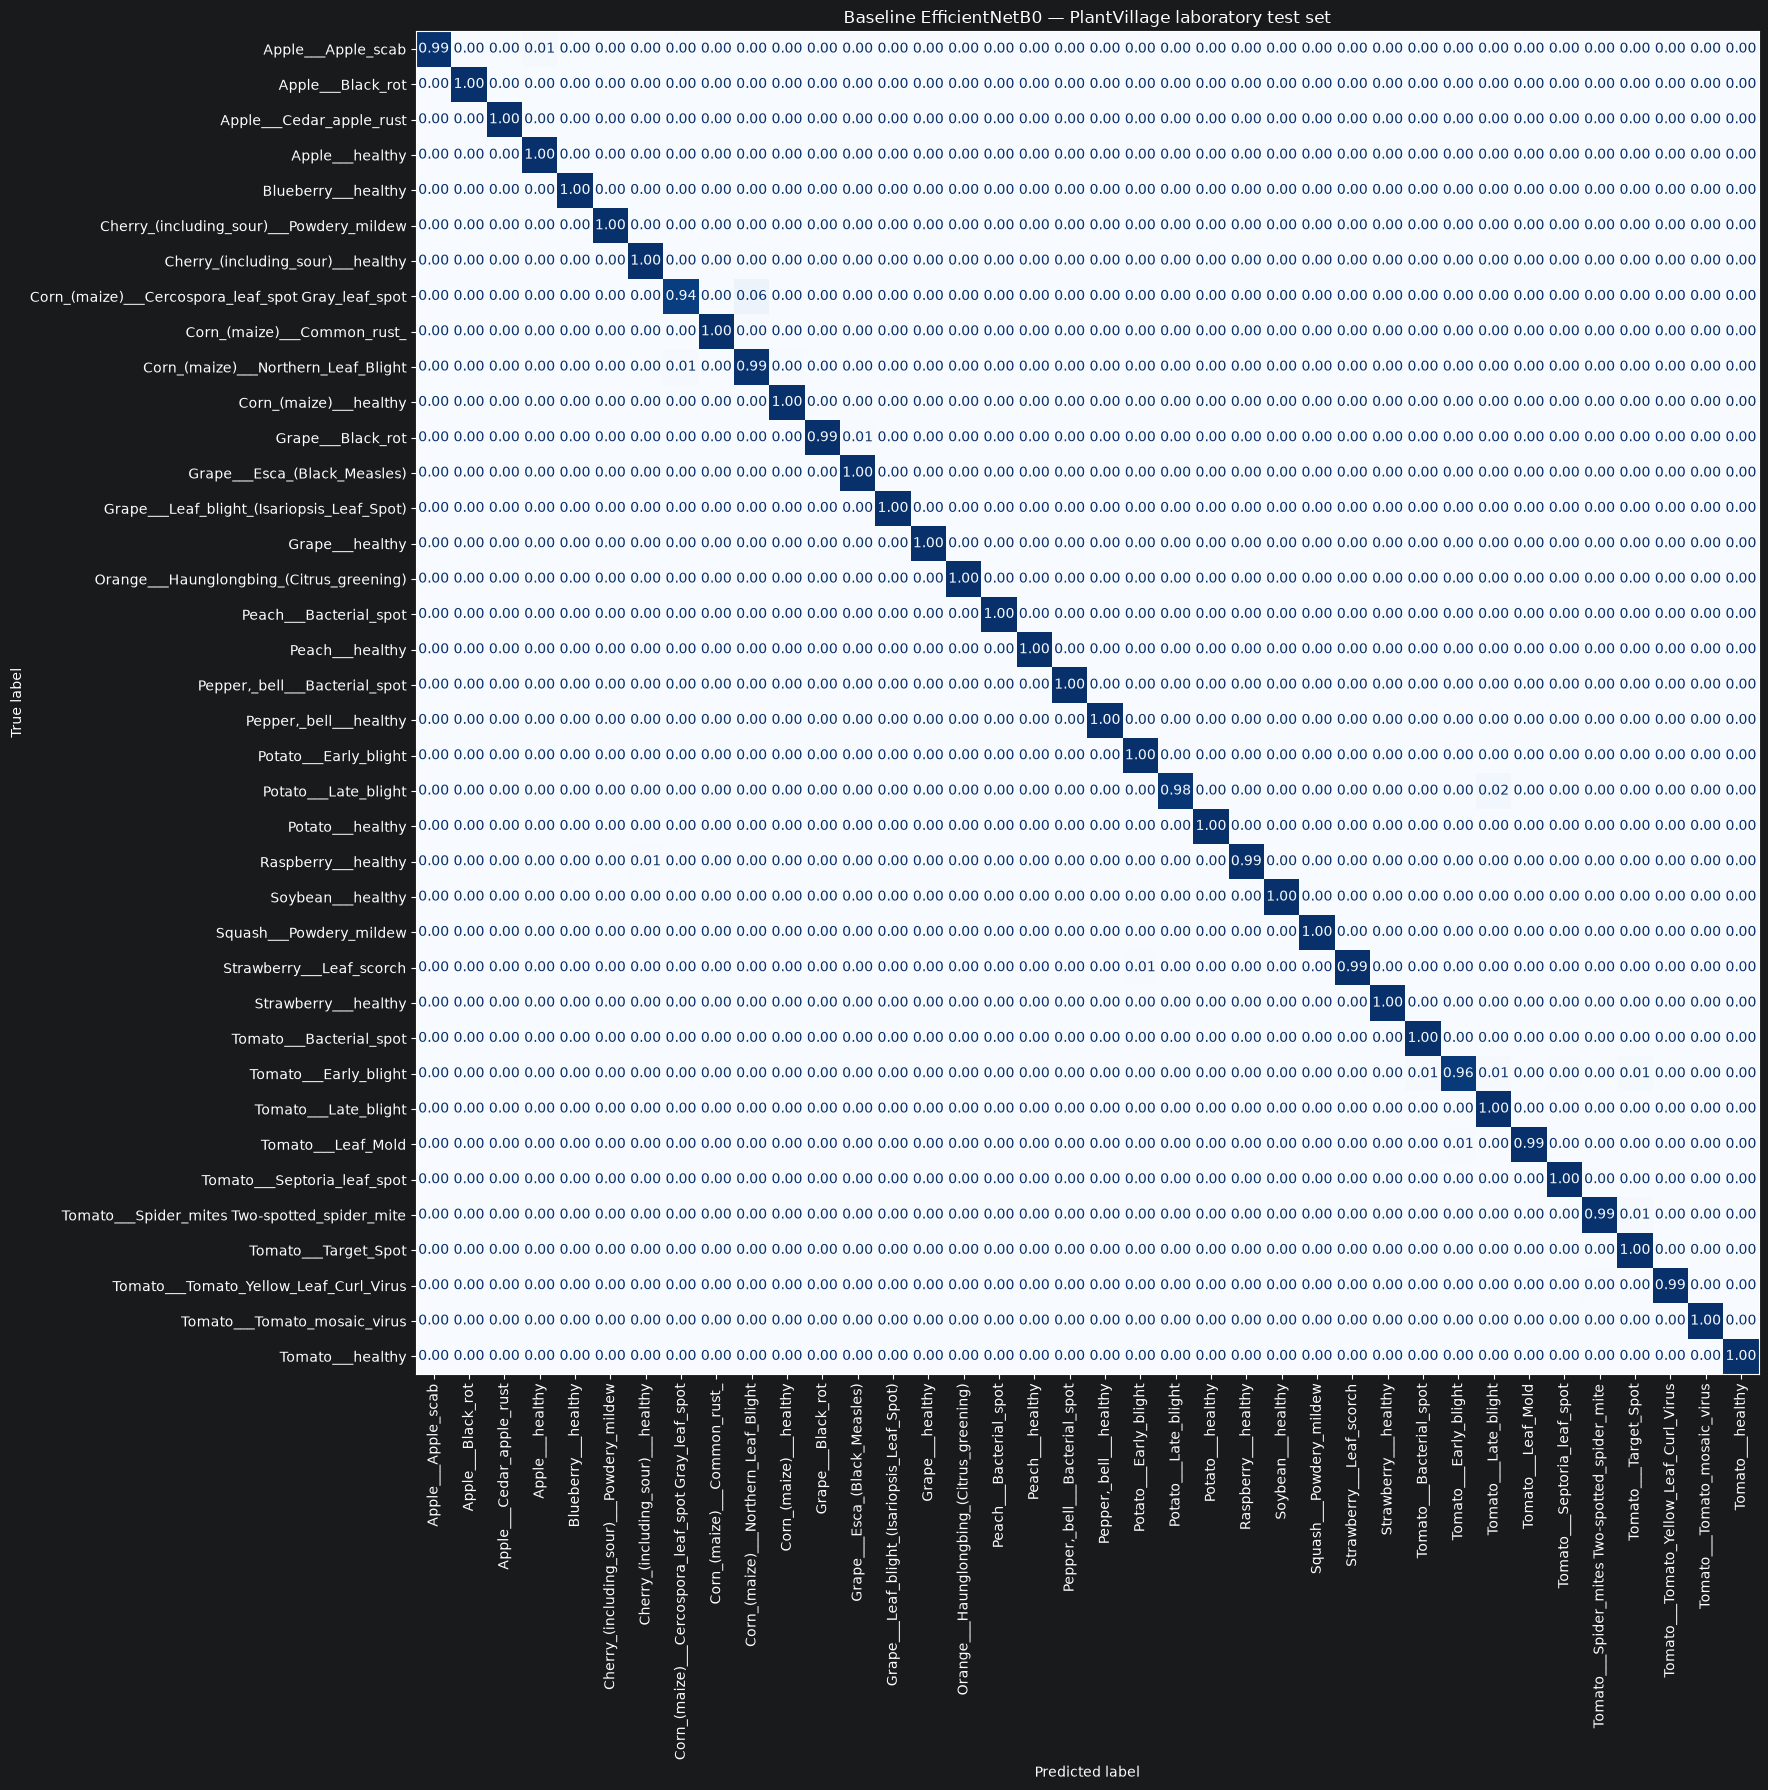

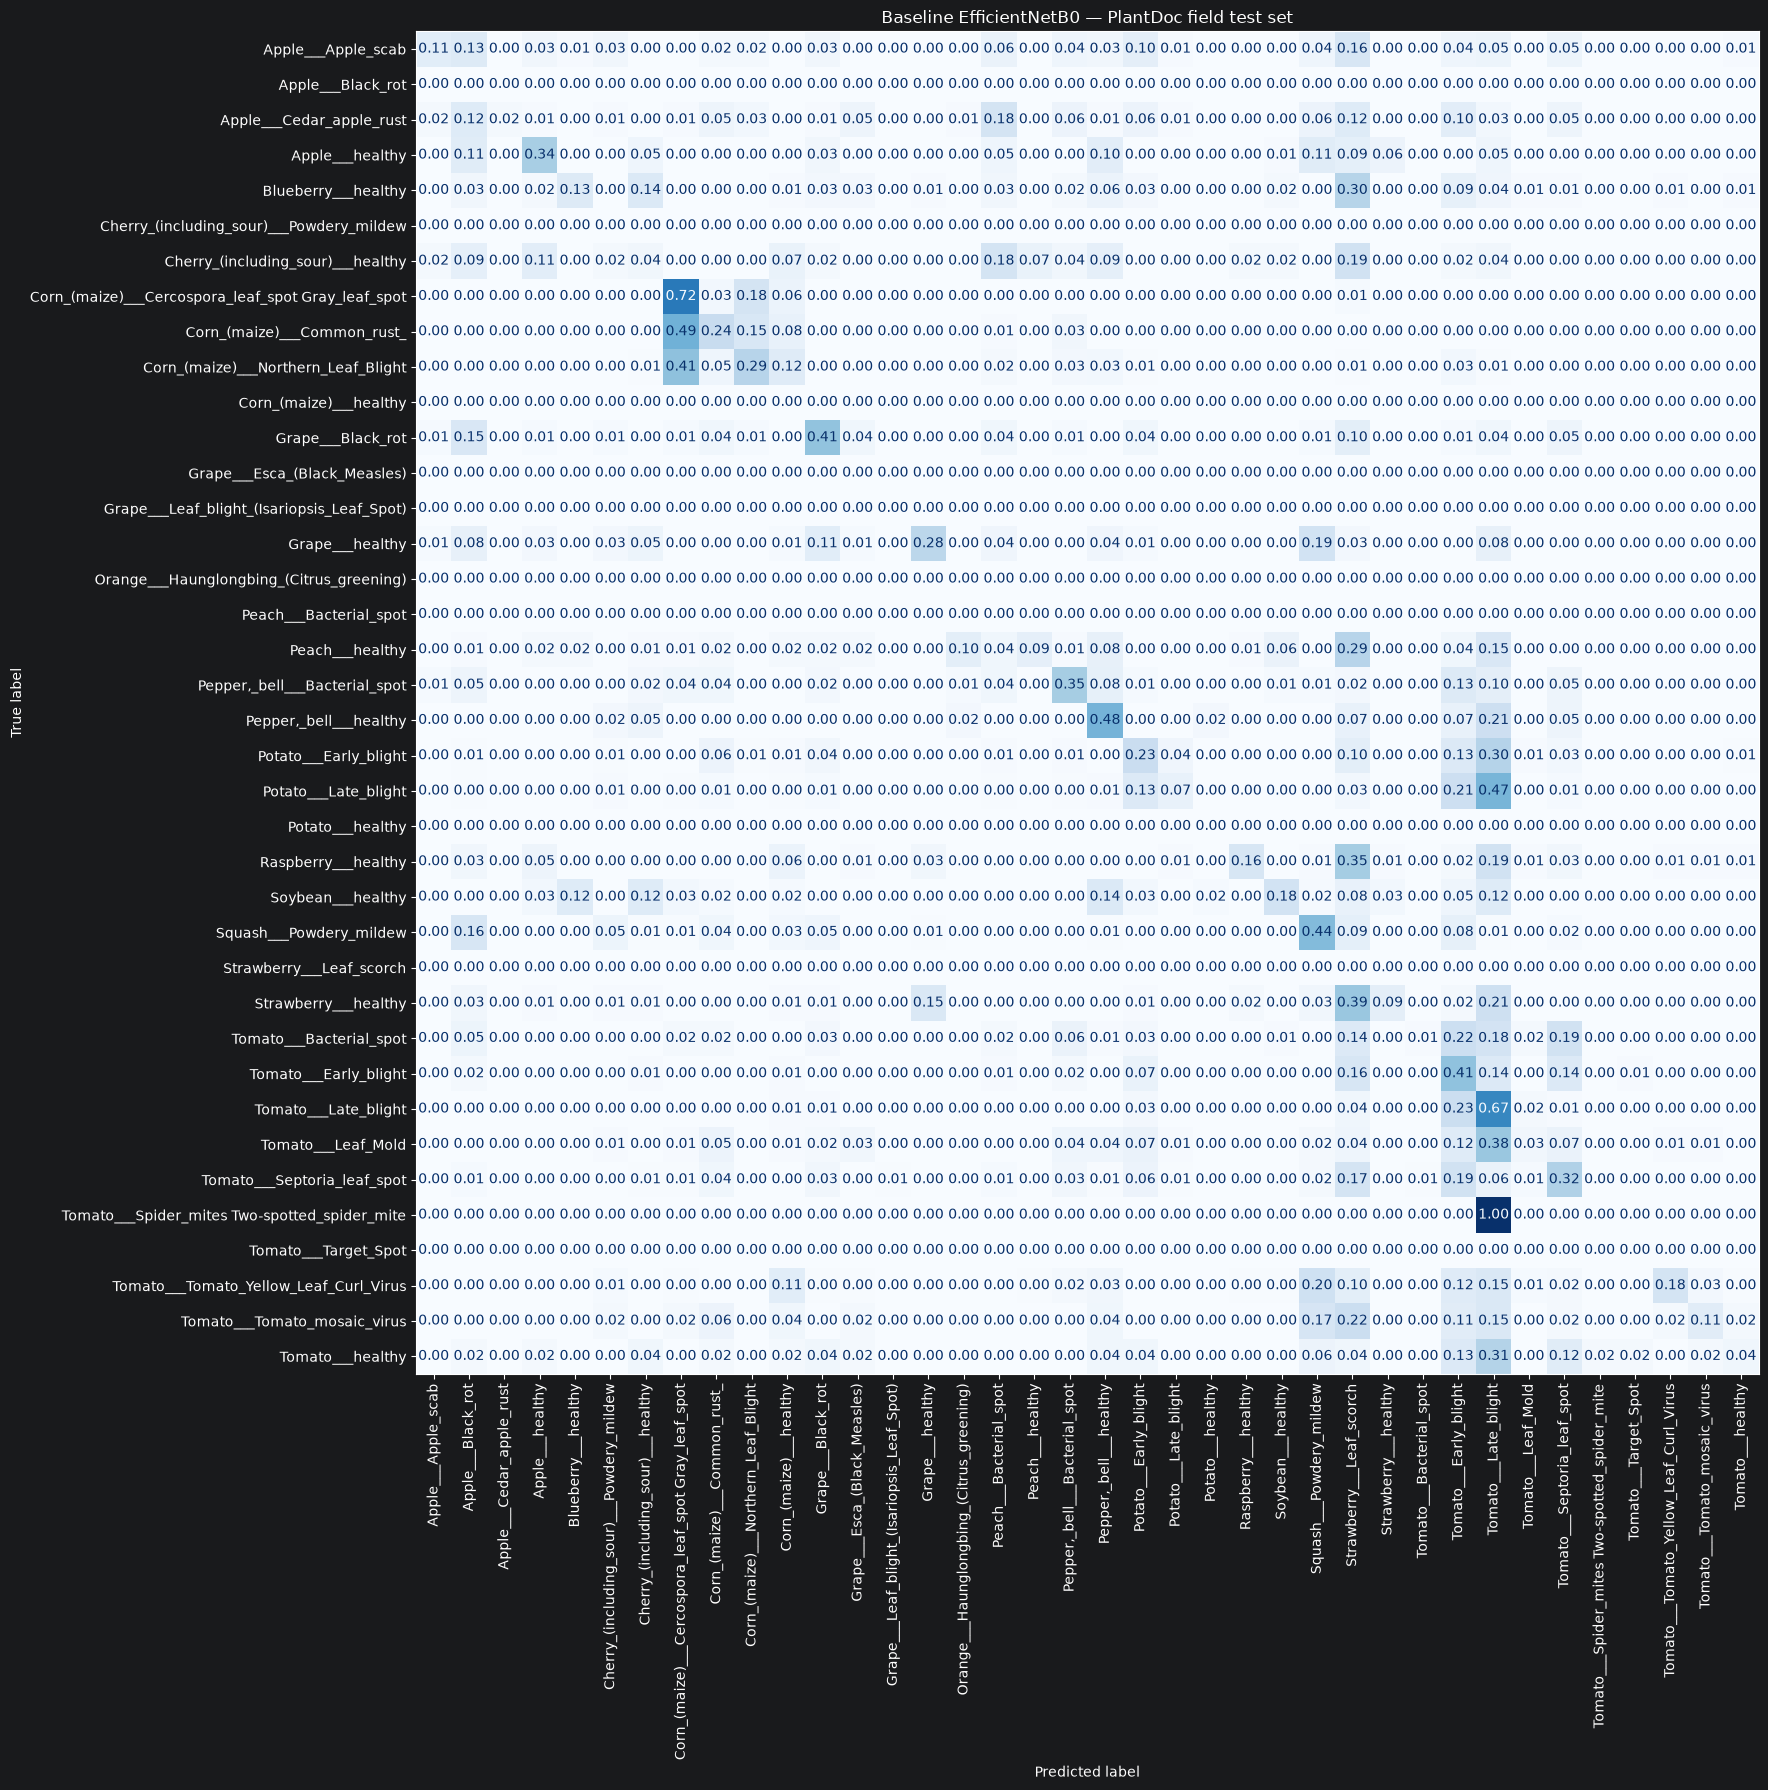

In [20]:
def plot_confusion_matrix_from_results(results, title, filename, normalize="true"):
    labels = np.arange(num_classes)
    cm = confusion_matrix(
        results["y_true"], results["y_pred"], labels=labels, normalize=normalize
    )

    fig, ax = plt.subplots(figsize=(18, 18))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        values_format=".2f" if normalize else "d",
        colorbar=False
    )
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(AUG_PLOTS_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_confusion_matrix_from_results(
    lab_results,
    "Baseline EfficientNetB0 — PlantVillage laboratory test set",
    "baseline_lab_confusion_matrix.png"
)

if field_results is not None:
    plot_confusion_matrix_from_results(
        field_results,
        "Baseline EfficientNetB0 — PlantDoc field test set",
        "baseline_field_confusion_matrix.png"
    )
else:
    print("PlantDoc field results are unavailable; field confusion matrix skipped.")


## 21. Define the four augmentation strategies

The experiments isolate four augmentation groups so that their effect on field generalisation can be compared fairly:

1. **Geometry:** horizontal flip, rotation, translation and zoom.
2. **Colour/lighting:** brightness and contrast changes.
3. **Noise/blur:** mild pixel noise and probabilistic Gaussian blur.
4. **Combined:** geometry + colour/lighting + noise/blur.

The custom noise layer is used instead of `keras.layers.GaussianNoise` so that noise can be specified directly on the 0–255 image scale without the Keras 3 `stddev <= 1` restriction.


In [21]:
@tf.keras.utils.register_keras_serializable(package="RQ7_2")
class RandomPixelGaussianNoise(tf.keras.layers.Layer):
    """Add Gaussian noise on the 0-255 image scale during training only."""
    def __init__(self, stddev=7.5, **kwargs):
        super().__init__(**kwargs)
        self.stddev = float(stddev)

    def get_config(self):
        config = super().get_config()
        config.update({"stddev": self.stddev})
        return config

    def call(self, inputs, training=None):
        if training is False or training is None:
            return inputs
        noise = tf.random.normal(tf.shape(inputs), mean=0.0, stddev=self.stddev, dtype=inputs.dtype)
        return tf.clip_by_value(inputs + noise, 0.0, 255.0)


@tf.keras.utils.register_keras_serializable(package="RQ7_2")
class RandomGaussianBlur(tf.keras.layers.Layer):
    """Apply Gaussian blur to a random subset of training images."""
    def __init__(self, probability=0.35, kernel_size=5, sigma=1.0, **kwargs):
        super().__init__(**kwargs)
        self.probability = float(probability)
        self.kernel_size = int(kernel_size)
        self.sigma = float(sigma)

    def get_config(self):
        config = super().get_config()
        config.update({
            "probability": self.probability,
            "kernel_size": self.kernel_size,
            "sigma": self.sigma,
        })
        return config

    def _blur(self, images):
        radius = self.kernel_size // 2
        x = tf.range(-radius, radius + 1, dtype=tf.float32)
        kernel_1d = tf.exp(-(x ** 2) / (2.0 * self.sigma ** 2))
        kernel_1d /= tf.reduce_sum(kernel_1d)
        kernel_2d = tf.tensordot(kernel_1d, kernel_1d, axes=0)
        kernel_2d = kernel_2d[:, :, tf.newaxis, tf.newaxis]
        kernel_2d = tf.tile(kernel_2d, [1, 1, 3, 1])
        return tf.nn.depthwise_conv2d(images, kernel_2d, strides=[1, 1, 1, 1], padding="SAME")

    def call(self, inputs, training=None):
        if training is False or training is None:
            return inputs
        blurred = self._blur(inputs)
        batch_size = tf.shape(inputs)[0]
        mask = tf.random.uniform([batch_size, 1, 1, 1]) < self.probability
        return tf.where(mask, blurred, inputs)


def make_geometry_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.08, fill_mode="reflect"),
        tf.keras.layers.RandomTranslation(0.08, 0.08, fill_mode="reflect"),
        tf.keras.layers.RandomZoom(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10), fill_mode="reflect"),
    ], name="geometry_augmentation")


def make_colour_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomBrightness(factor=0.20, value_range=(0.0, 255.0)),
        tf.keras.layers.RandomContrast(factor=0.20),
    ], name="colour_lighting_augmentation")


def make_noise_blur_augmentation():
    return tf.keras.Sequential([
        RandomPixelGaussianNoise(stddev=7.5),
        RandomGaussianBlur(probability=0.35, kernel_size=5, sigma=1.0),
    ], name="noise_blur_augmentation")


def make_combined_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.08, fill_mode="reflect"),
        tf.keras.layers.RandomTranslation(0.08, 0.08, fill_mode="reflect"),
        tf.keras.layers.RandomZoom(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10), fill_mode="reflect"),
        tf.keras.layers.RandomBrightness(factor=0.20, value_range=(0.0, 255.0)),
        tf.keras.layers.RandomContrast(factor=0.20),
        RandomPixelGaussianNoise(stddev=7.5),
        RandomGaussianBlur(probability=0.35, kernel_size=5, sigma=1.0),
    ], name="combined_augmentation")


AUGMENTATION_FACTORIES = {
    "Geometry": make_geometry_augmentation,
    "Colour_Lighting": make_colour_augmentation,
    "Noise_Blur": make_noise_blur_augmentation,
    "Combined": make_combined_augmentation,
}

for strategy, factory in AUGMENTATION_FACTORIES.items():
    print(f"{strategy}: {factory().name}")


Geometry: geometry_augmentation
Colour_Lighting: colour_lighting_augmentation
Noise_Blur: noise_blur_augmentation
Combined: combined_augmentation


## 22. EfficientNetB0 model and training functions for controlled experiments

Each augmentation experiment starts from a **fresh ImageNet-pretrained EfficientNetB0**. The classifier head and the 65%/35% freeze/fine-tune policy match the existing baseline so that augmentation is the principal experimental change.


In [22]:
def create_augmented_model(num_classes, augmentation_layer, strategy_name):
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augmentation_layer(inputs)

    base = tf.keras.applications.EfficientNetB0(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base.trainable = False

    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(
        num_classes, activation="softmax", name="classifier"
    )(x)

    model = tf.keras.Model(
        inputs, outputs,
        name=f"rq7_2_efficientnetb0_{strategy_name.lower()}"
    )
    return model, base


def make_experiment_callbacks(model_path):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(model_path), monitor="val_accuracy", mode="max",
            save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOP_PATIENCE,
            min_delta=MIN_DELTA, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=5,
            min_lr=1e-7, verbose=1
        )
    ]


def train_augmentation_experiment(strategy_name, augmentation_factory):
    print("\n" + "=" * 72)
    print(f"TRAINING EFFICIENTNETB0 AUGMENTATION STRATEGY: {strategy_name}")
    print("=" * 72)

    tf.keras.backend.clear_session()
    gc.collect()
    tf.random.set_seed(SEED)

    augmentation_layer = augmentation_factory()
    model, base_model_aug = create_augmented_model(
        num_classes, augmentation_layer, strategy_name
    )

    model_path = AUG_MODEL_DIR / f"{strategy_name.lower()}_best_model.keras"
    callbacks_aug = make_experiment_callbacks(model_path)
    callbacks_aug.append(TrainingResourceLogger(strategy_name))

    # Phase 1: same classification-head training policy as baseline.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=BASE_LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    history_warmup_aug = model.fit(
        train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS,
        class_weight=class_weight, callbacks=callbacks_aug
    )

    # Phase 2: fine-tune the upper 35% of EfficientNetB0, matching baseline.
    base_model_aug.trainable = True
    freeze_until = int(len(base_model_aug.layers) * 0.65)
    for layer in base_model_aug.layers[:freeze_until]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    history_finetune_aug = model.fit(
        train_ds, validation_data=val_ds,
        initial_epoch=WARMUP_EPOCHS, epochs=MAX_EPOCHS,
        class_weight=class_weight, callbacks=callbacks_aug
    )

    del model, base_model_aug, callbacks_aug
    gc.collect()

    # Custom augmentation layers are registered above, so the saved model
    # can be loaded normally in the same notebook/session.
    trained_model = tf.keras.models.load_model(model_path)
    return trained_model, model_path, history_warmup_aug, history_finetune_aug


## 23. Retrain and evaluate every augmentation strategy

Each independently trained model is evaluated on the **same unchanged PlantVillage laboratory test set** and the **same PlantDoc field test set**. Accuracy and macro-F1 are recorded, followed by the laboratory-to-field drop in percentage points.


In [23]:
augmentation_results = {}
experiment_rows = []

if field_results is not None:
    experiment_rows.append({
        "Model": "EfficientNetB0",
        "Augmentation": "None (Baseline)",
        "Lab Accuracy (%)": lab_results["accuracy"] * 100,
        "Field Accuracy (%)": field_results["accuracy"] * 100,
        "Accuracy Drop (pp)": (lab_results["accuracy"] - field_results["accuracy"]) * 100,
        "Lab Macro-F1 (%)": lab_results["macro_f1"] * 100,
        "Field Macro-F1 (%)": field_results["macro_f1"] * 100,
        "Macro-F1 Drop (pp)": (lab_results["macro_f1"] - field_results["macro_f1"]) * 100,
    })

if not RUN_AUGMENTATION_EXPERIMENTS:
    print("RUN_AUGMENTATION_EXPERIMENTS=False — training skipped.")
elif field_results is None:
    raise RuntimeError(
        "PlantDoc field evaluation must be available before running the augmentation comparison. Run Section 16 first."
    )
else:
    for strategy_name, augmentation_factory in AUGMENTATION_FACTORIES.items():
        trained_model, model_path, hist1, hist2 = train_augmentation_experiment(
            strategy_name, augmentation_factory
        )

        lab_aug = evaluate_dataset(trained_model, lab_test_ds)
        field_aug = evaluate_dataset(trained_model, field_ds)

        accuracy_drop_aug = lab_aug["accuracy"] - field_aug["accuracy"]
        macro_f1_drop_aug = lab_aug["macro_f1"] - field_aug["macro_f1"]

        augmentation_results[strategy_name] = {
            "model_path": str(model_path),
            "lab": lab_aug,
            "field": field_aug,
            "history_warmup": hist1.history,
            "history_finetune": hist2.history,
        }

        experiment_rows.append({
            "Model": "EfficientNetB0",
            "Augmentation": strategy_name.replace("_", "/"),
            "Lab Accuracy (%)": lab_aug["accuracy"] * 100,
            "Field Accuracy (%)": field_aug["accuracy"] * 100,
            "Accuracy Drop (pp)": accuracy_drop_aug * 100,
            "Lab Macro-F1 (%)": lab_aug["macro_f1"] * 100,
            "Field Macro-F1 (%)": field_aug["macro_f1"] * 100,
            "Macro-F1 Drop (pp)": macro_f1_drop_aug * 100,
        })

        print(f"\n{strategy_name} RESULTS")
        print(f"Lab accuracy:     {lab_aug['accuracy']:.4f}")
        print(f"Field accuracy:   {field_aug['accuracy']:.4f}")
        print(f"Accuracy drop:    {accuracy_drop_aug * 100:.2f} pp")
        print(f"Lab macro-F1:     {lab_aug['macro_f1']:.4f}")
        print(f"Field macro-F1:   {field_aug['macro_f1']:.4f}")
        print(f"Macro-F1 drop:    {macro_f1_drop_aug * 100:.2f} pp")

        del trained_model
        gc.collect()

comparison_df = pd.DataFrame(experiment_rows).round(2)

if not comparison_df.empty:
    display(comparison_df)
    comparison_df.to_csv(
        AUG_REPORTS_DIR / "rq7_2_efficientnetb0_augmentation_comparison.csv",
        index=False
    )



TRAINING EFFICIENTNETB0 AUGMENTATION STRATEGY: Geometry
Epoch 1/8


/home/bonga/tf-test/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7873 - loss: 1.0372  
Epoch 1: val_accuracy improved from None to 0.83981, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras

Epoch 1: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 96s 155ms/step - accuracy: 0.7873 - loss: 1.0372 - val_accuracy: 0.8398 - val_loss: 0.5682 - learning_rate: 0.0010
Epoch 2/8
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.9082 - loss: 0.3648  
Epoch 2: val_accuracy improved from 0.83981 to 0.89141, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras

Epoch 2: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geo

/home/bonga/tf-test/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1793884858.917316     757 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/rq7_2_efficientnetb0_geometry_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9368 - loss: 0.1968  
Epoch 9: val_accuracy improved from 0.94485 to 0.96411, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras

Epoch 9: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 133s 215ms/step - accuracy: 0.9368 - loss: 0.1968 - val_accuracy: 0.9641 - val_loss: 0.1123 - learning_rate: 1.0000e-04
Epoch 10/100
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9709 - loss: 0.0783  
Epoch 10: val_accuracy improved from 0.96411 to 0.97902, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/geometry_best_model.keras

Epoch 10: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentati

2026-11-05 17:21:34.327050: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


... (12 outputs left out)

545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7815 - loss: 1.0695  
Epoch 1: val_accuracy improved from None to 0.78535, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras

Epoch 1: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 148s 253ms/step - accuracy: 0.7815 - loss: 1.0695 - val_accuracy: 0.7853 - val_loss: 0.7406 - learning_rate: 0.0010
Epoch 2/8
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.8964 - loss: 0.3996  
Epoch 2: val_accuracy improved from 0.78535 to 0.86320, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras

Epoch 2: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/co

/home/bonga/tf-test/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1793899717.686661     757 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/rq7_2_efficientnetb0_combined_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.9294 - loss: 0.2189  
Epoch 9: val_accuracy improved from 0.92226 to 0.94037, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras

Epoch 9: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras
545/545 ━━━━━━━━━━━━━━━━━━━━ 150s 243ms/step - accuracy: 0.9294 - loss: 0.2189 - val_accuracy: 0.9404 - val_loss: 0.1931 - learning_rate: 1.0000e-04
Epoch 10/100
545/545 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9619 - loss: 0.1020  
Epoch 10: val_accuracy improved from 0.94037 to 0.96961, saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentation_models/combined_best_model.keras

Epoch 10: finished saving model to /mnt/d/M IT/runs/rq7_2_efficientnetb0_baseline_no_augmentation_20261105_141118/augmentati

,Model,Augmentation,Lab Accuracy (%),Field Accuracy (%),Accuracy Drop (pp),Lab Macro-F1 (%),Field Macro-F1 (%),Macro-F1 Drop (pp)
0,EfficientNetB0,None (Baseline),99.55,22.90,76.66,99.43,16.62,82.81
1,EfficientNetB0,Geometry,99.35,22.21,77.14,99.17,15.93,83.24
2,EfficientNetB0,Colour/Lighting,99.45,22.07,77.38,99.24,15.67,83.57
3,EfficientNetB0,Noise/Blur,99.58,20.91,78.67,99.40,15.09,84.31
4,EfficientNetB0,Combined,99.28,23.07,76.21,99.00,16.37,82.63


## 24. Confusion matrices for all augmentation experiments

These matrices show whether each augmentation changes the class-level error pattern on both laboratory and field images.


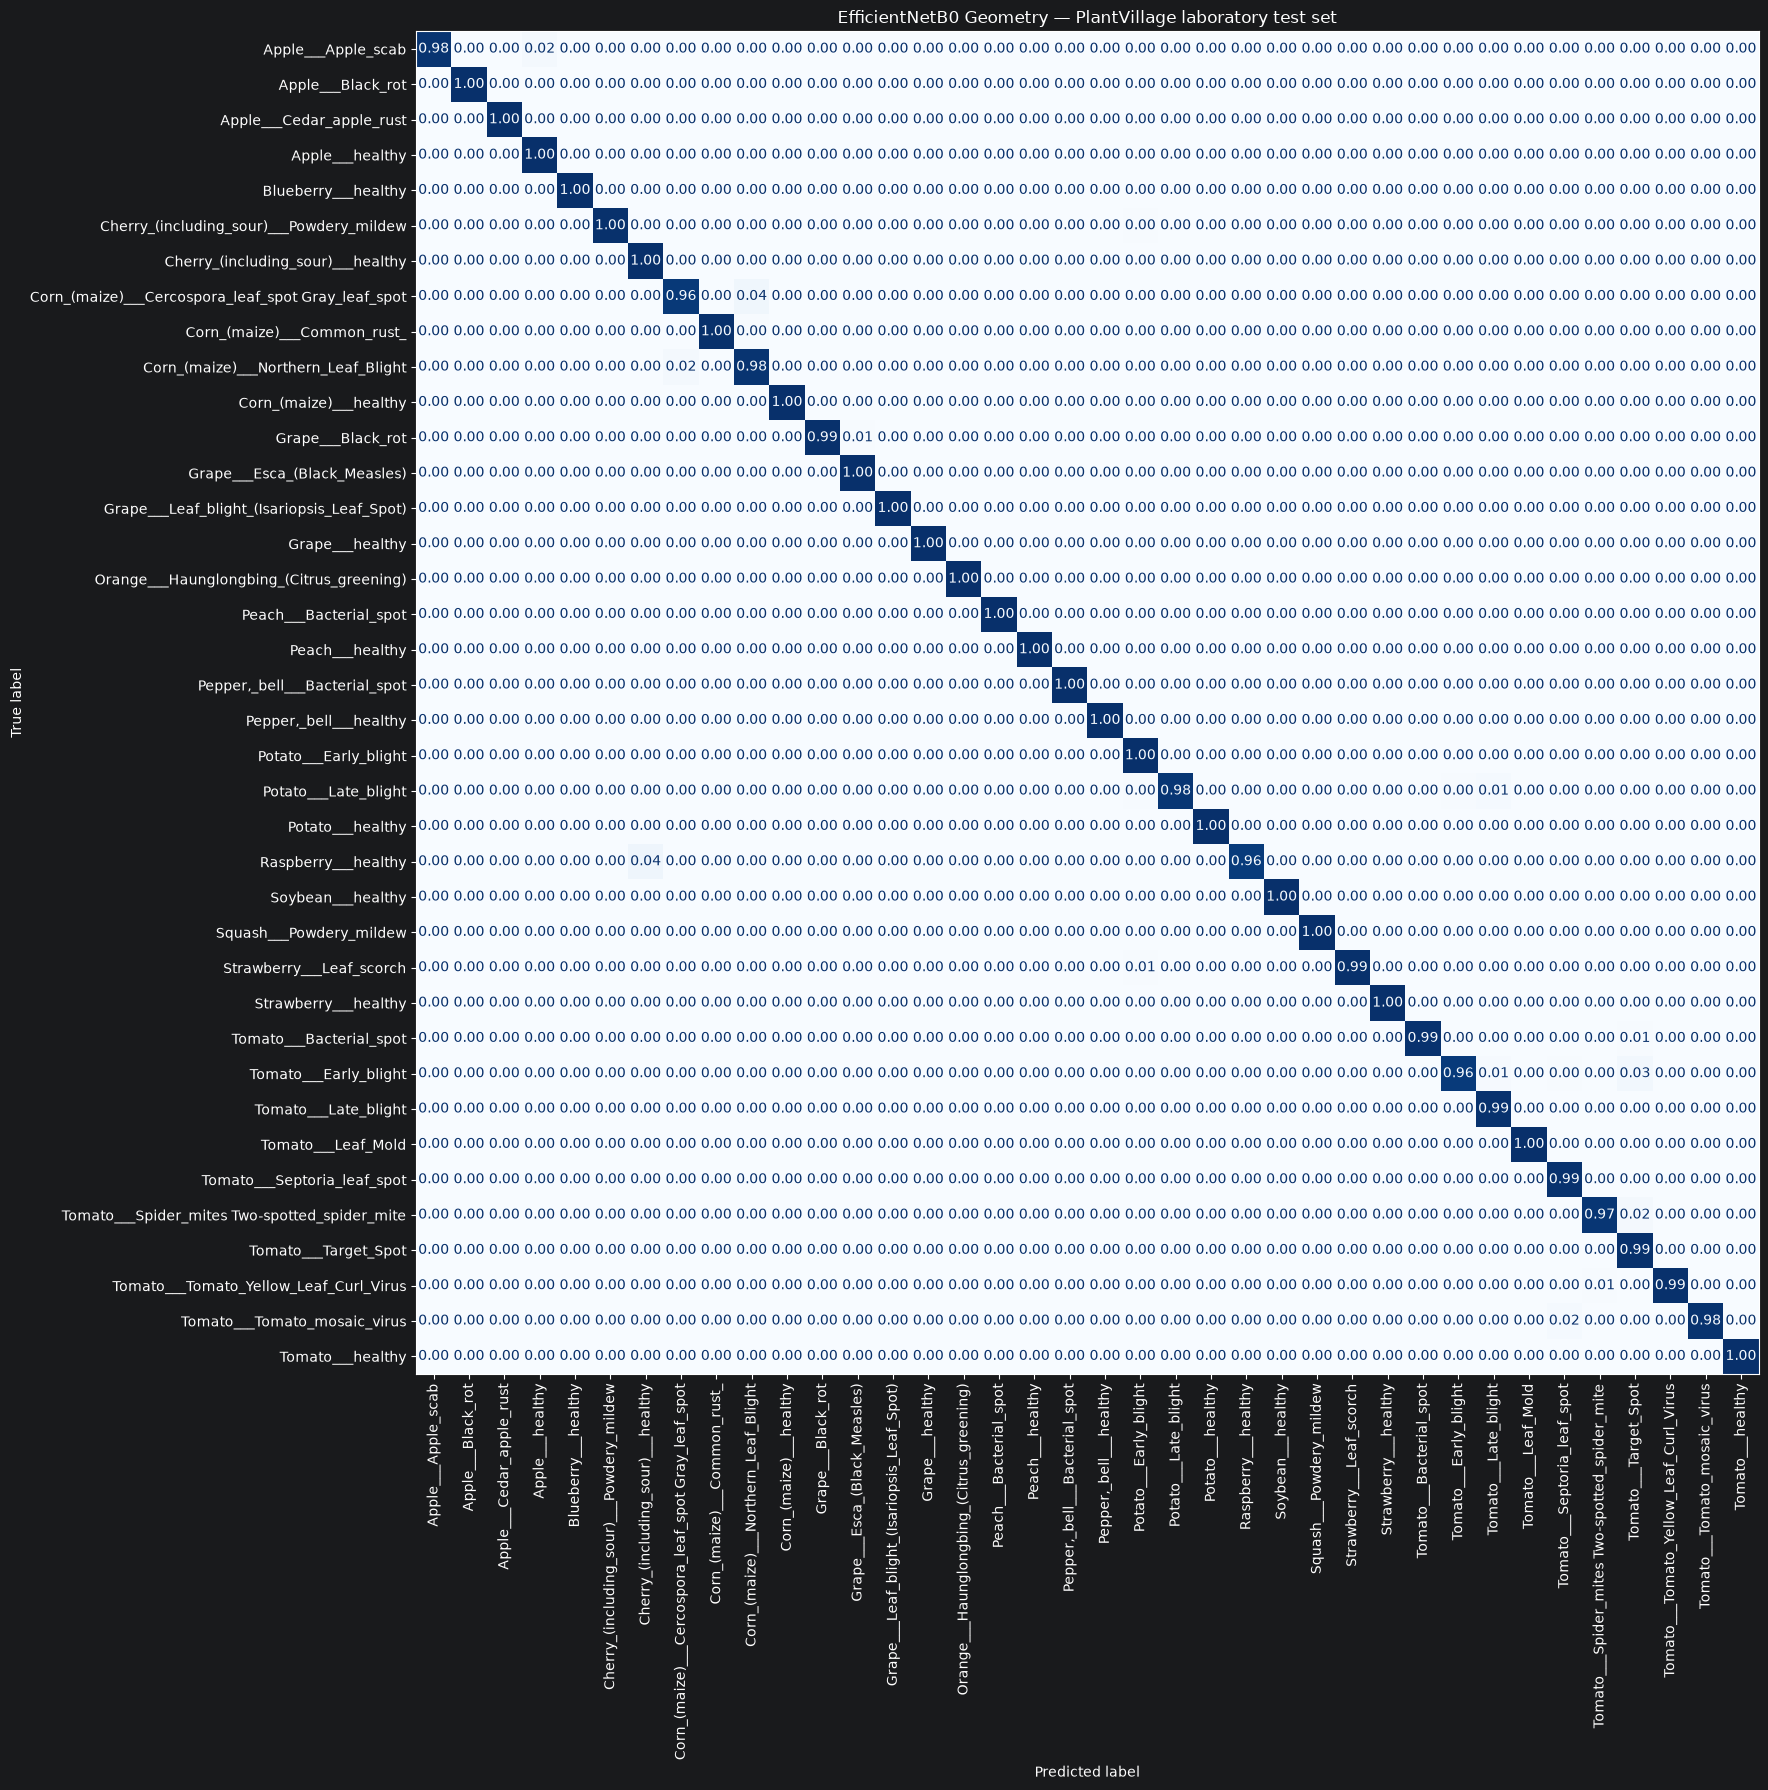

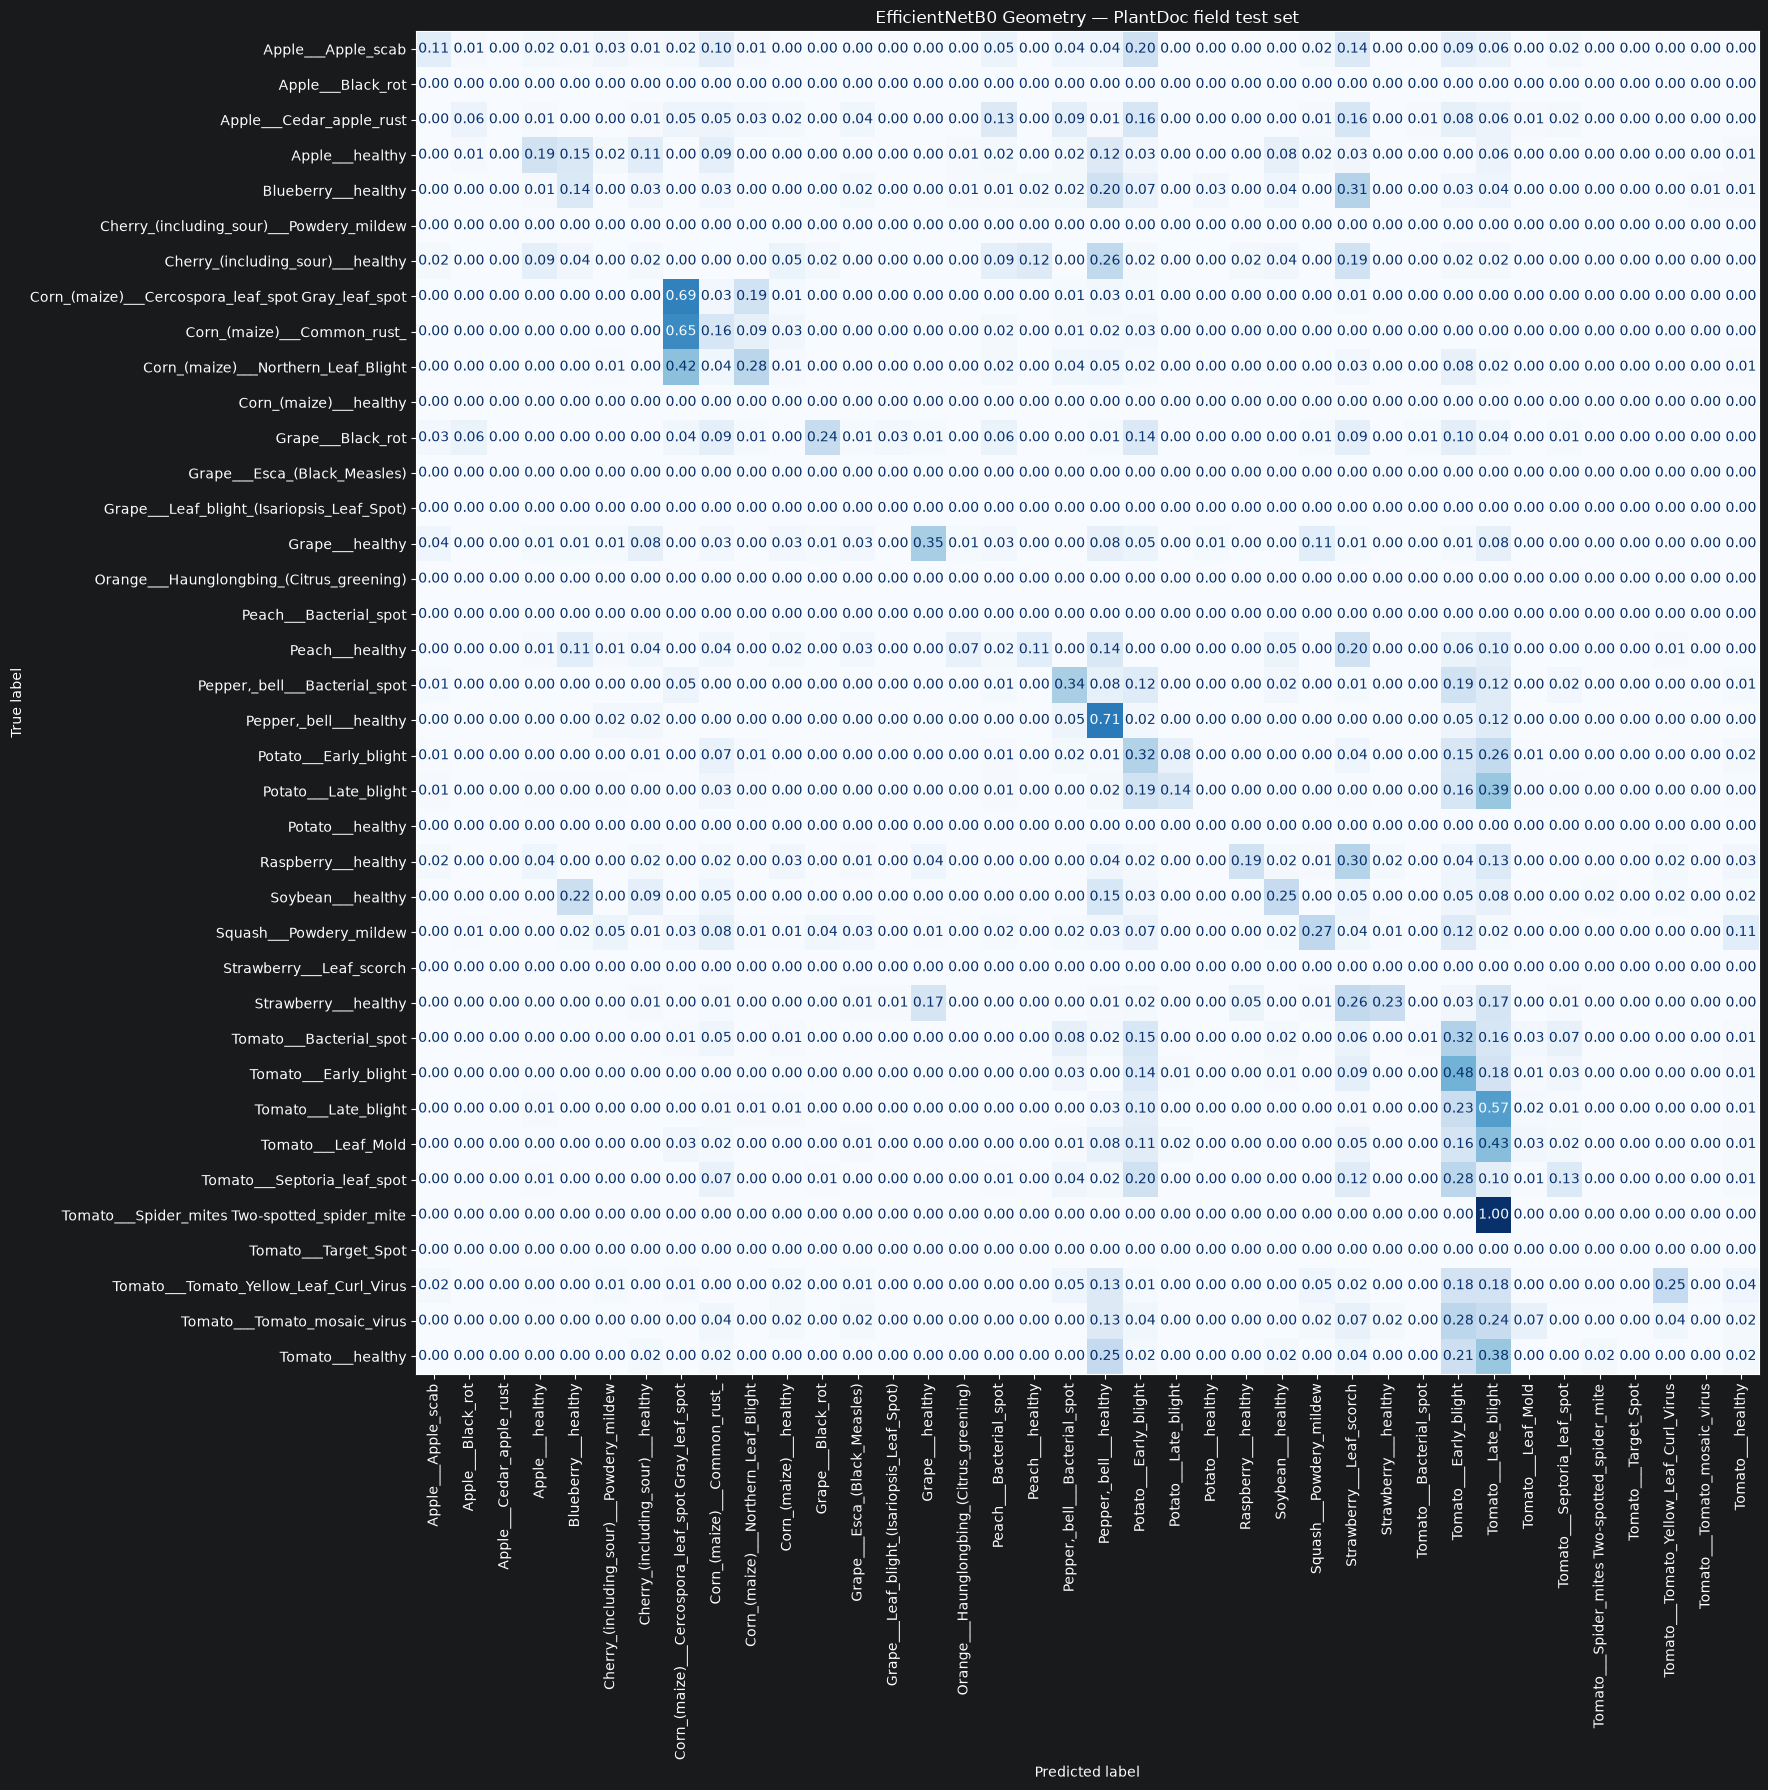

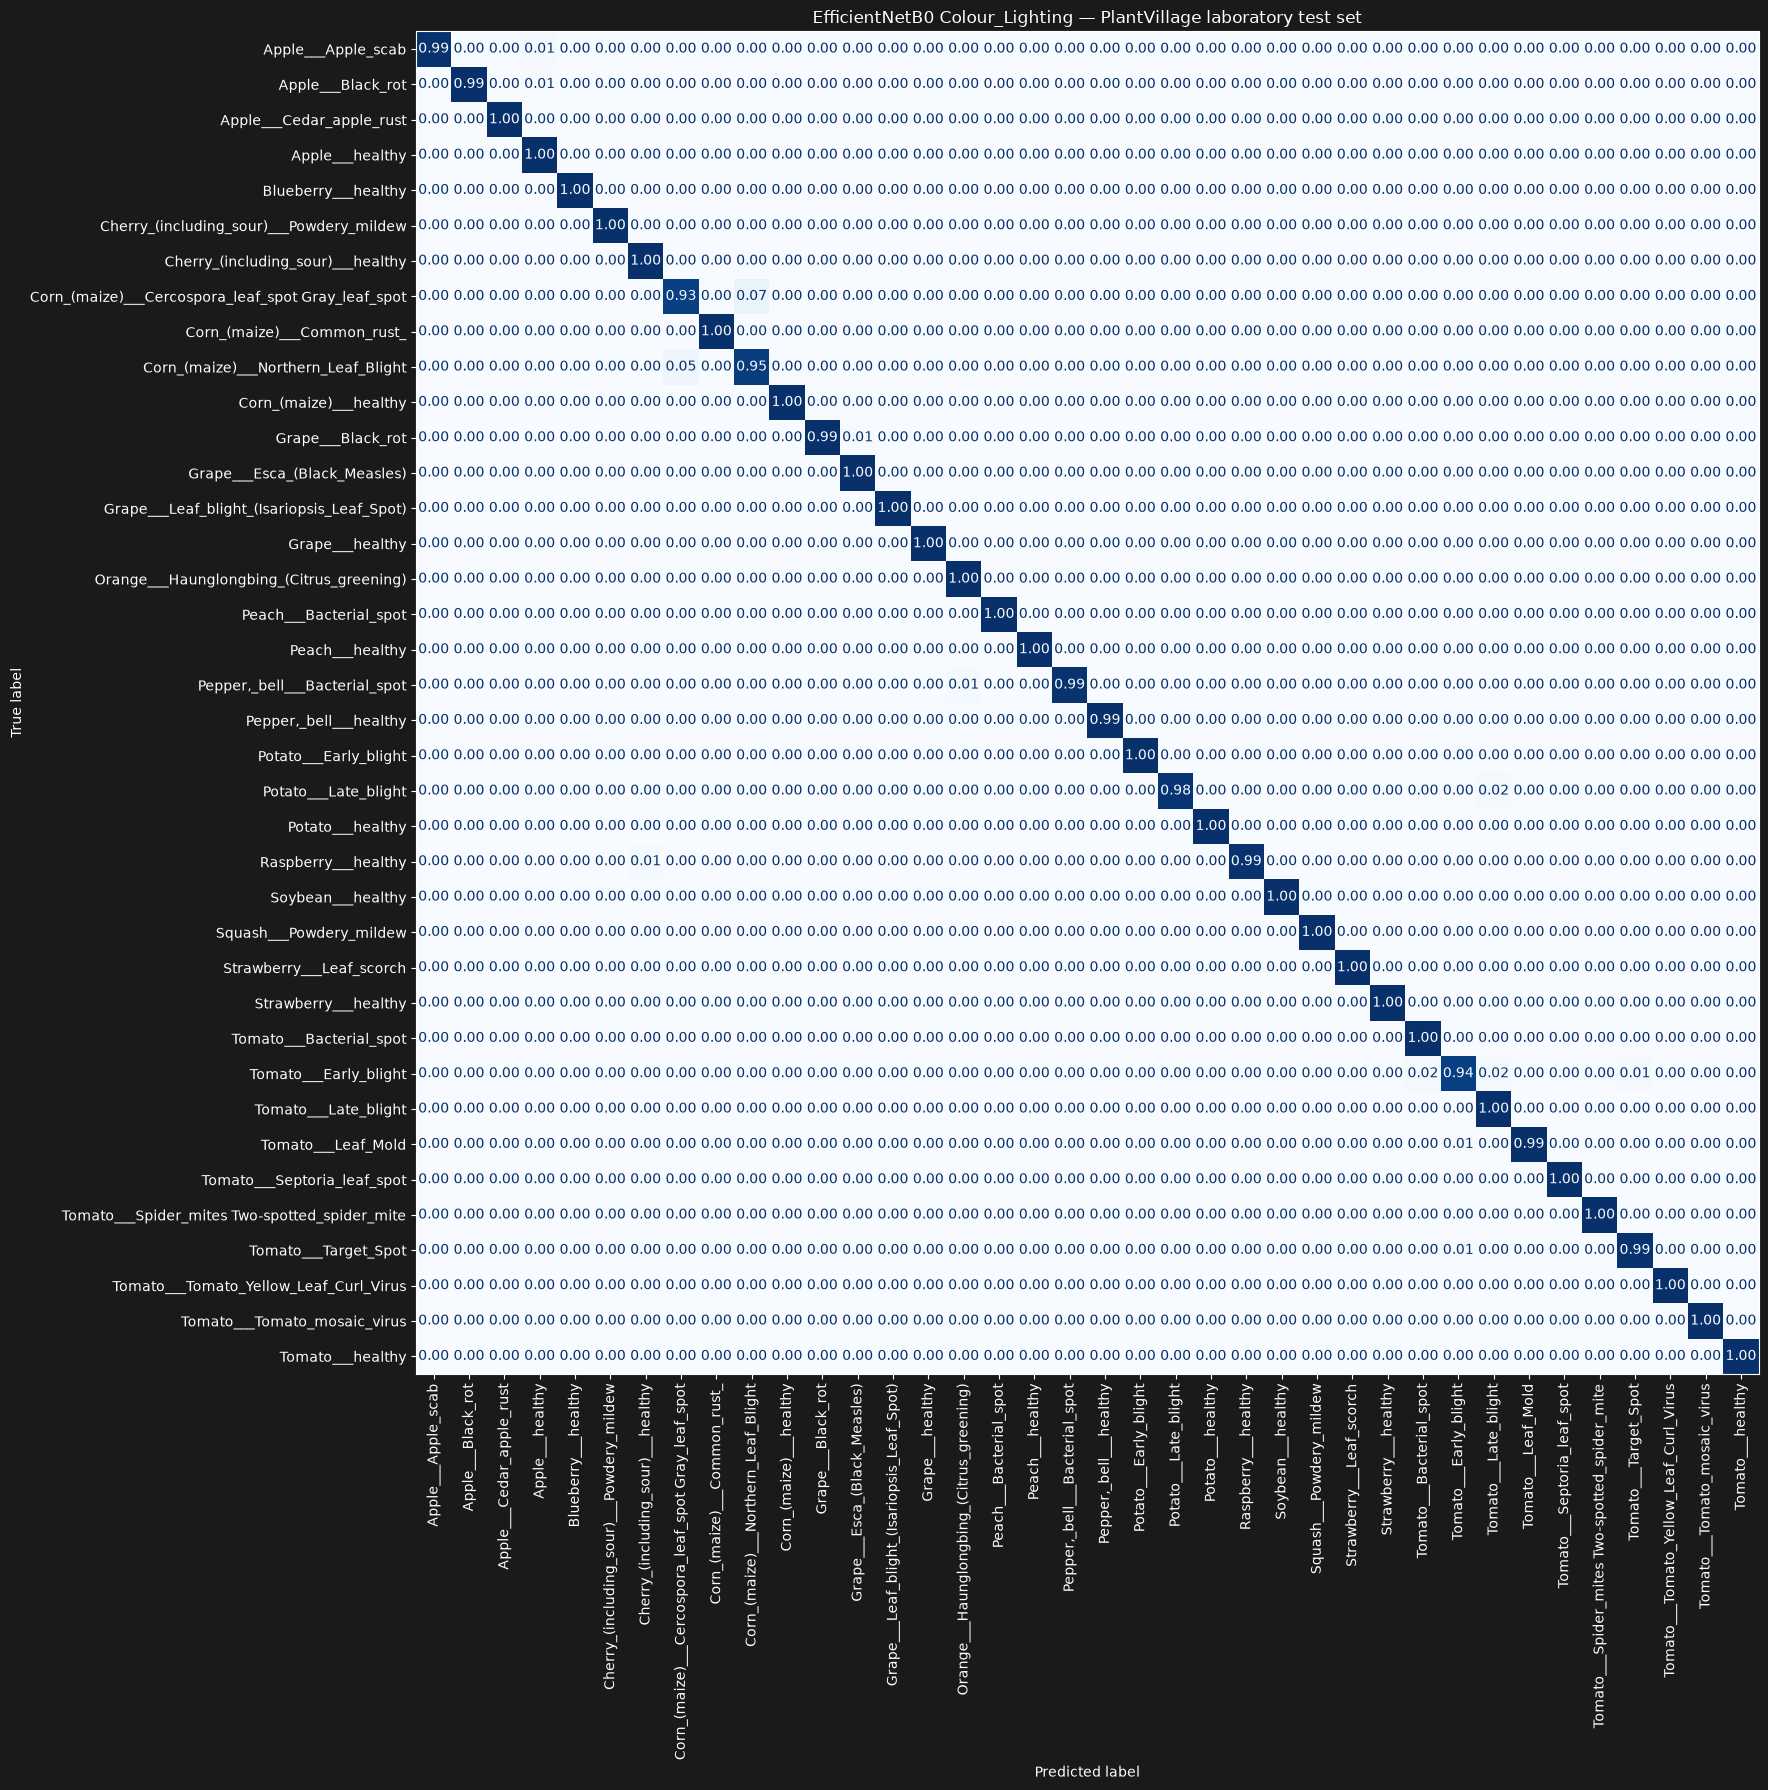

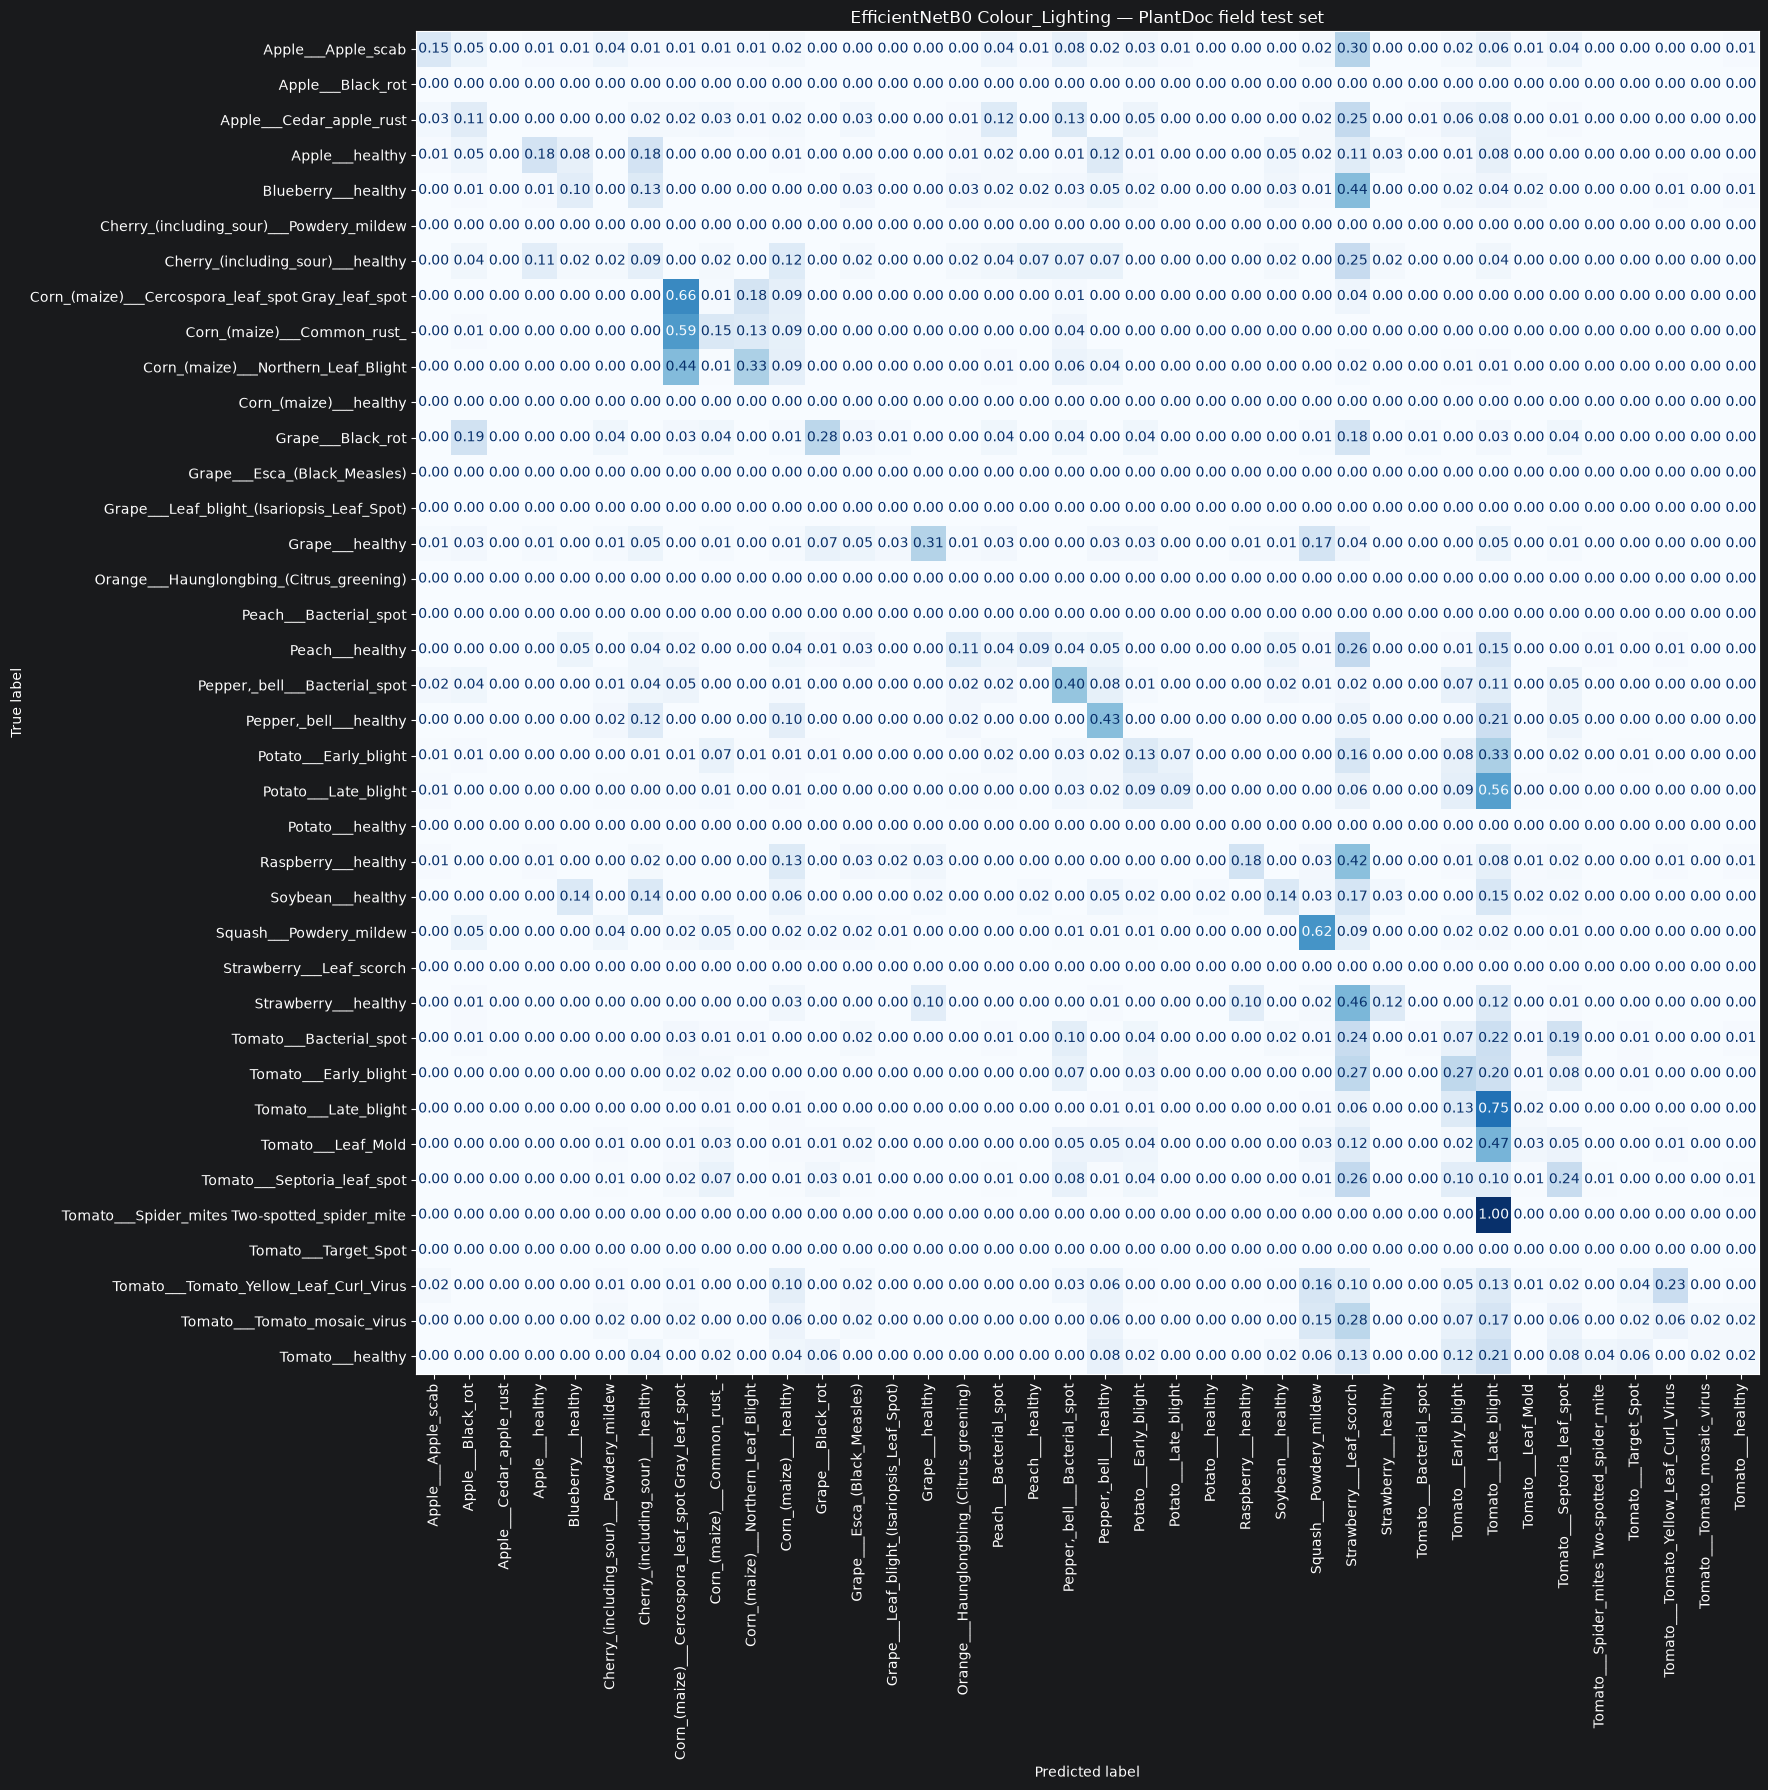

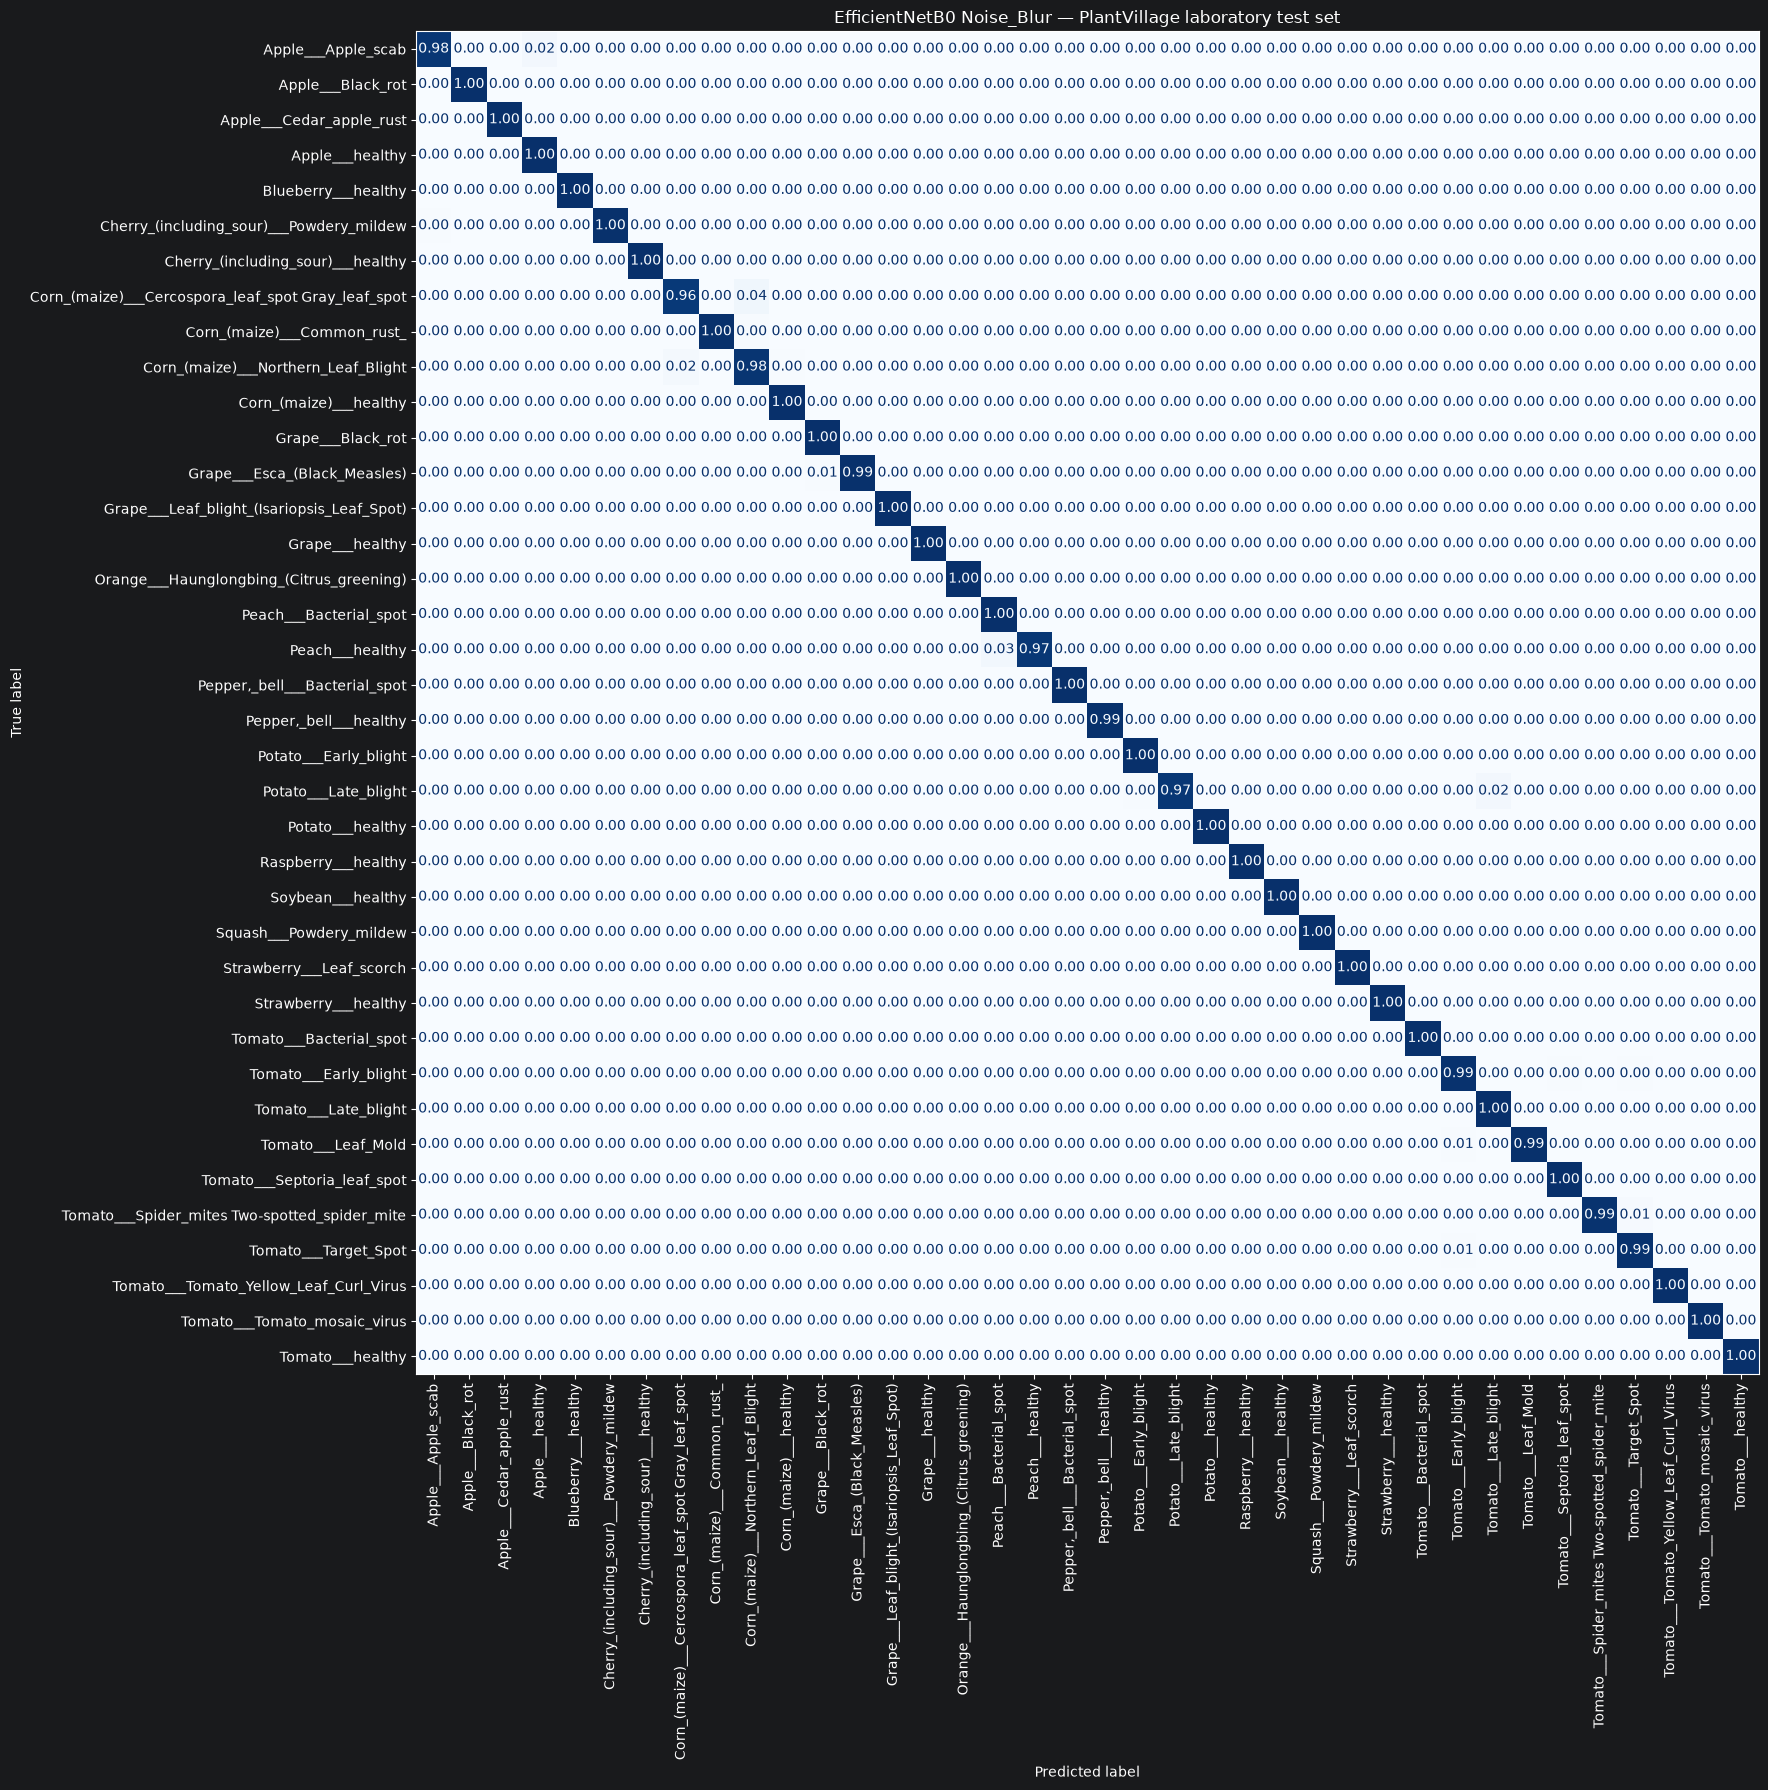

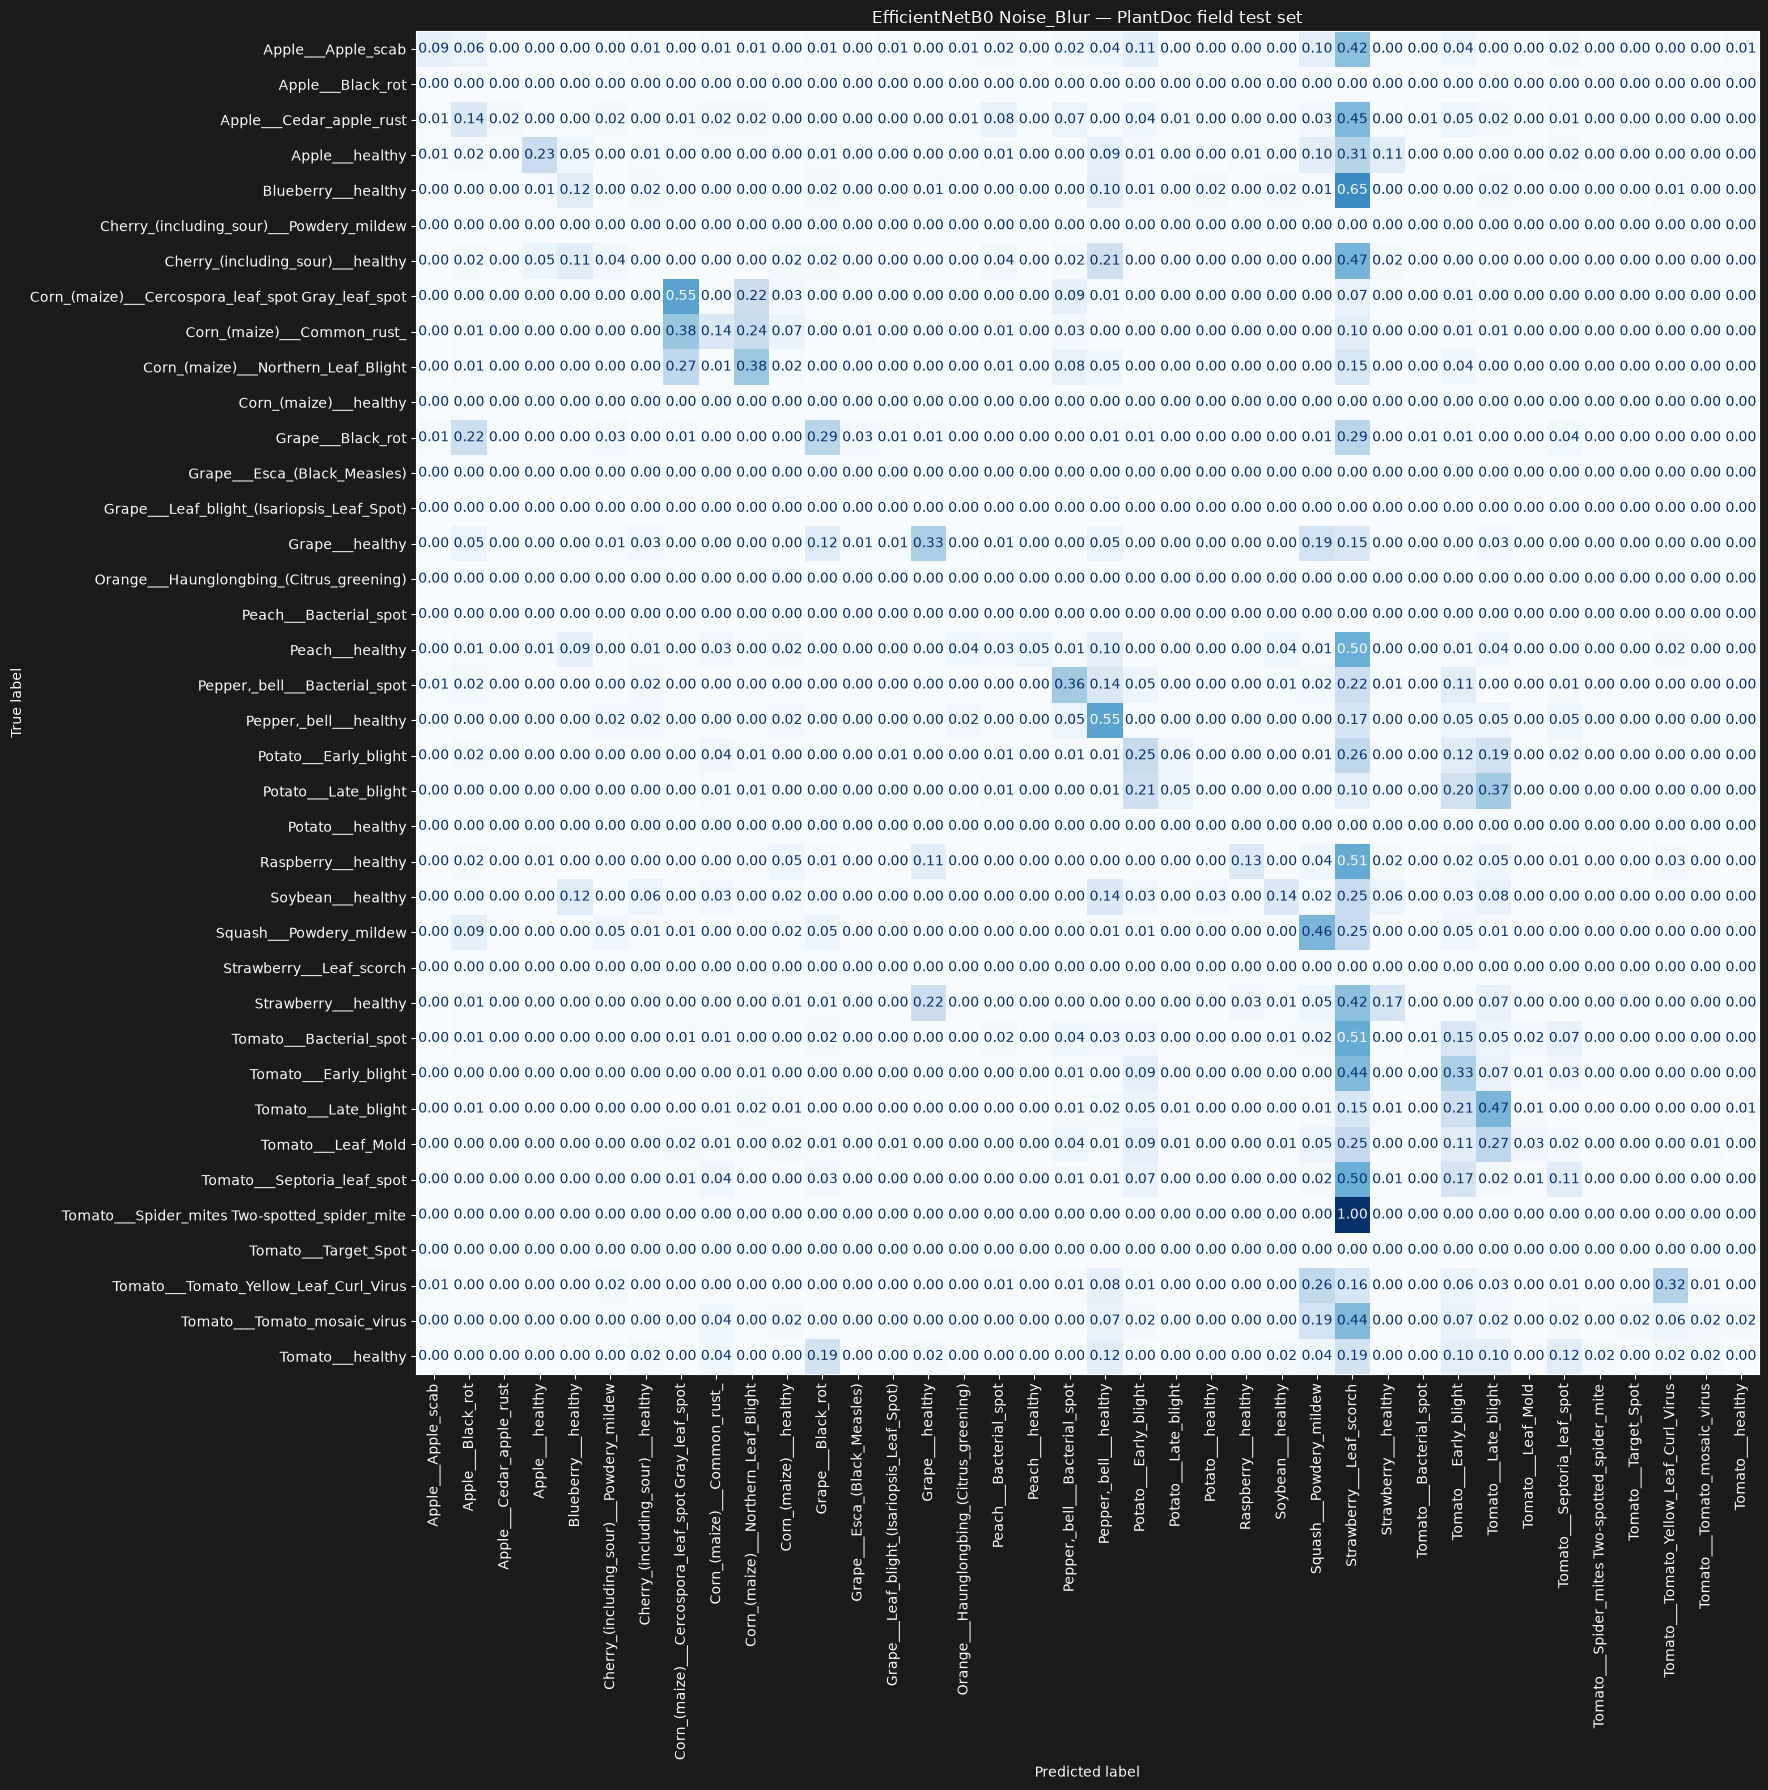

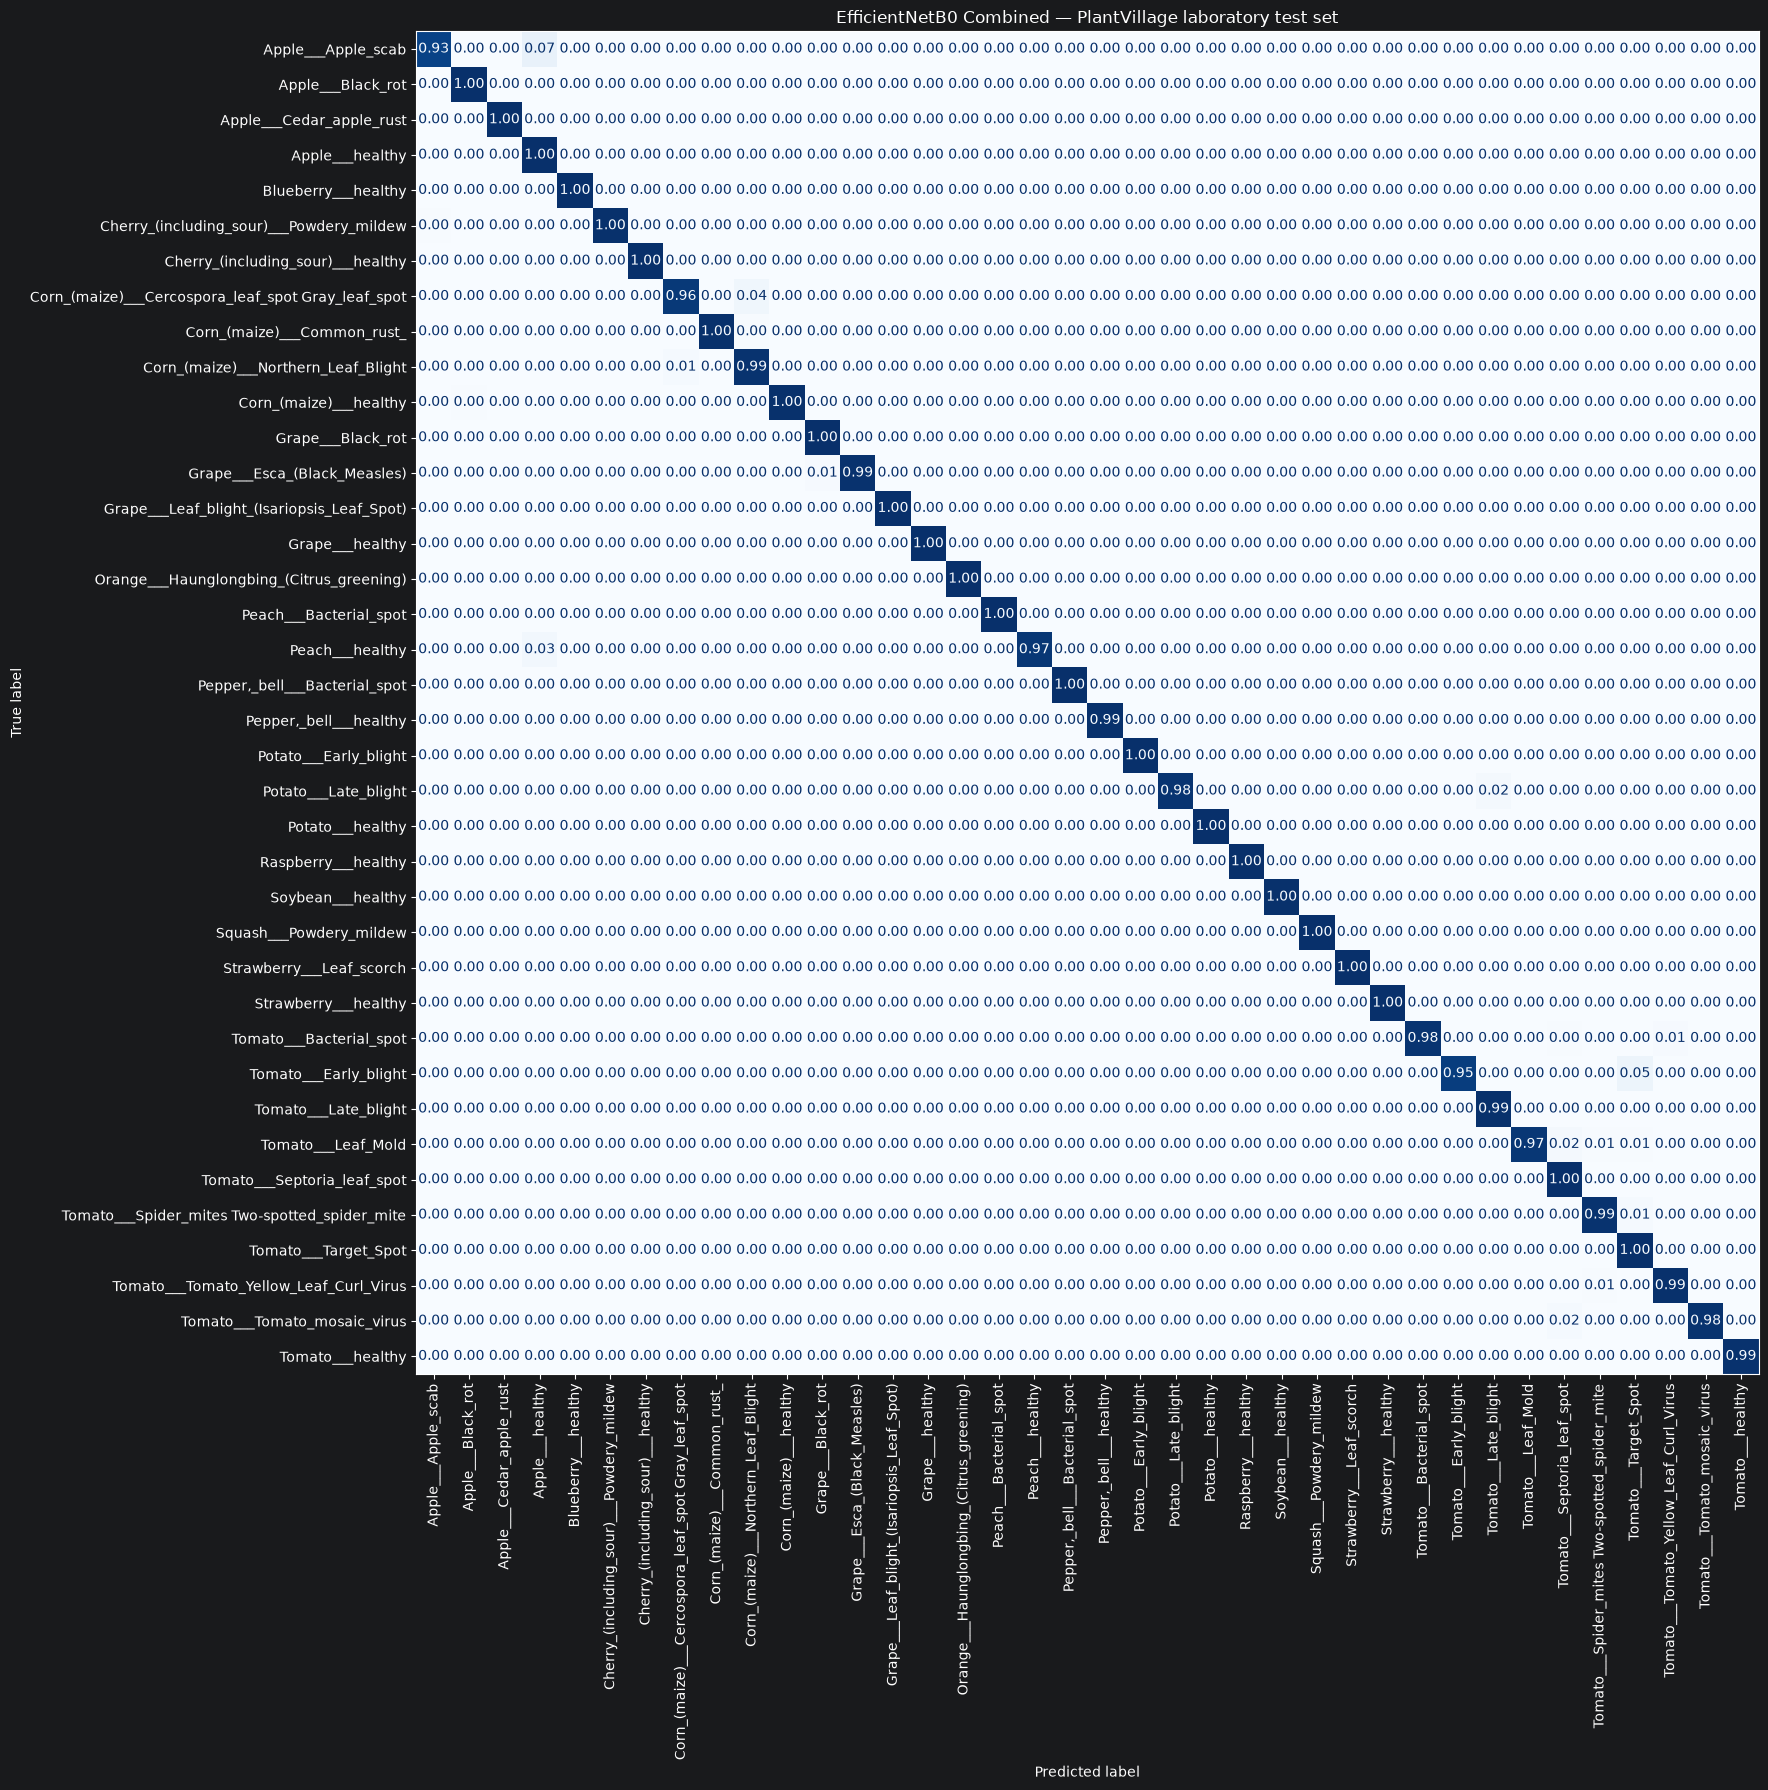

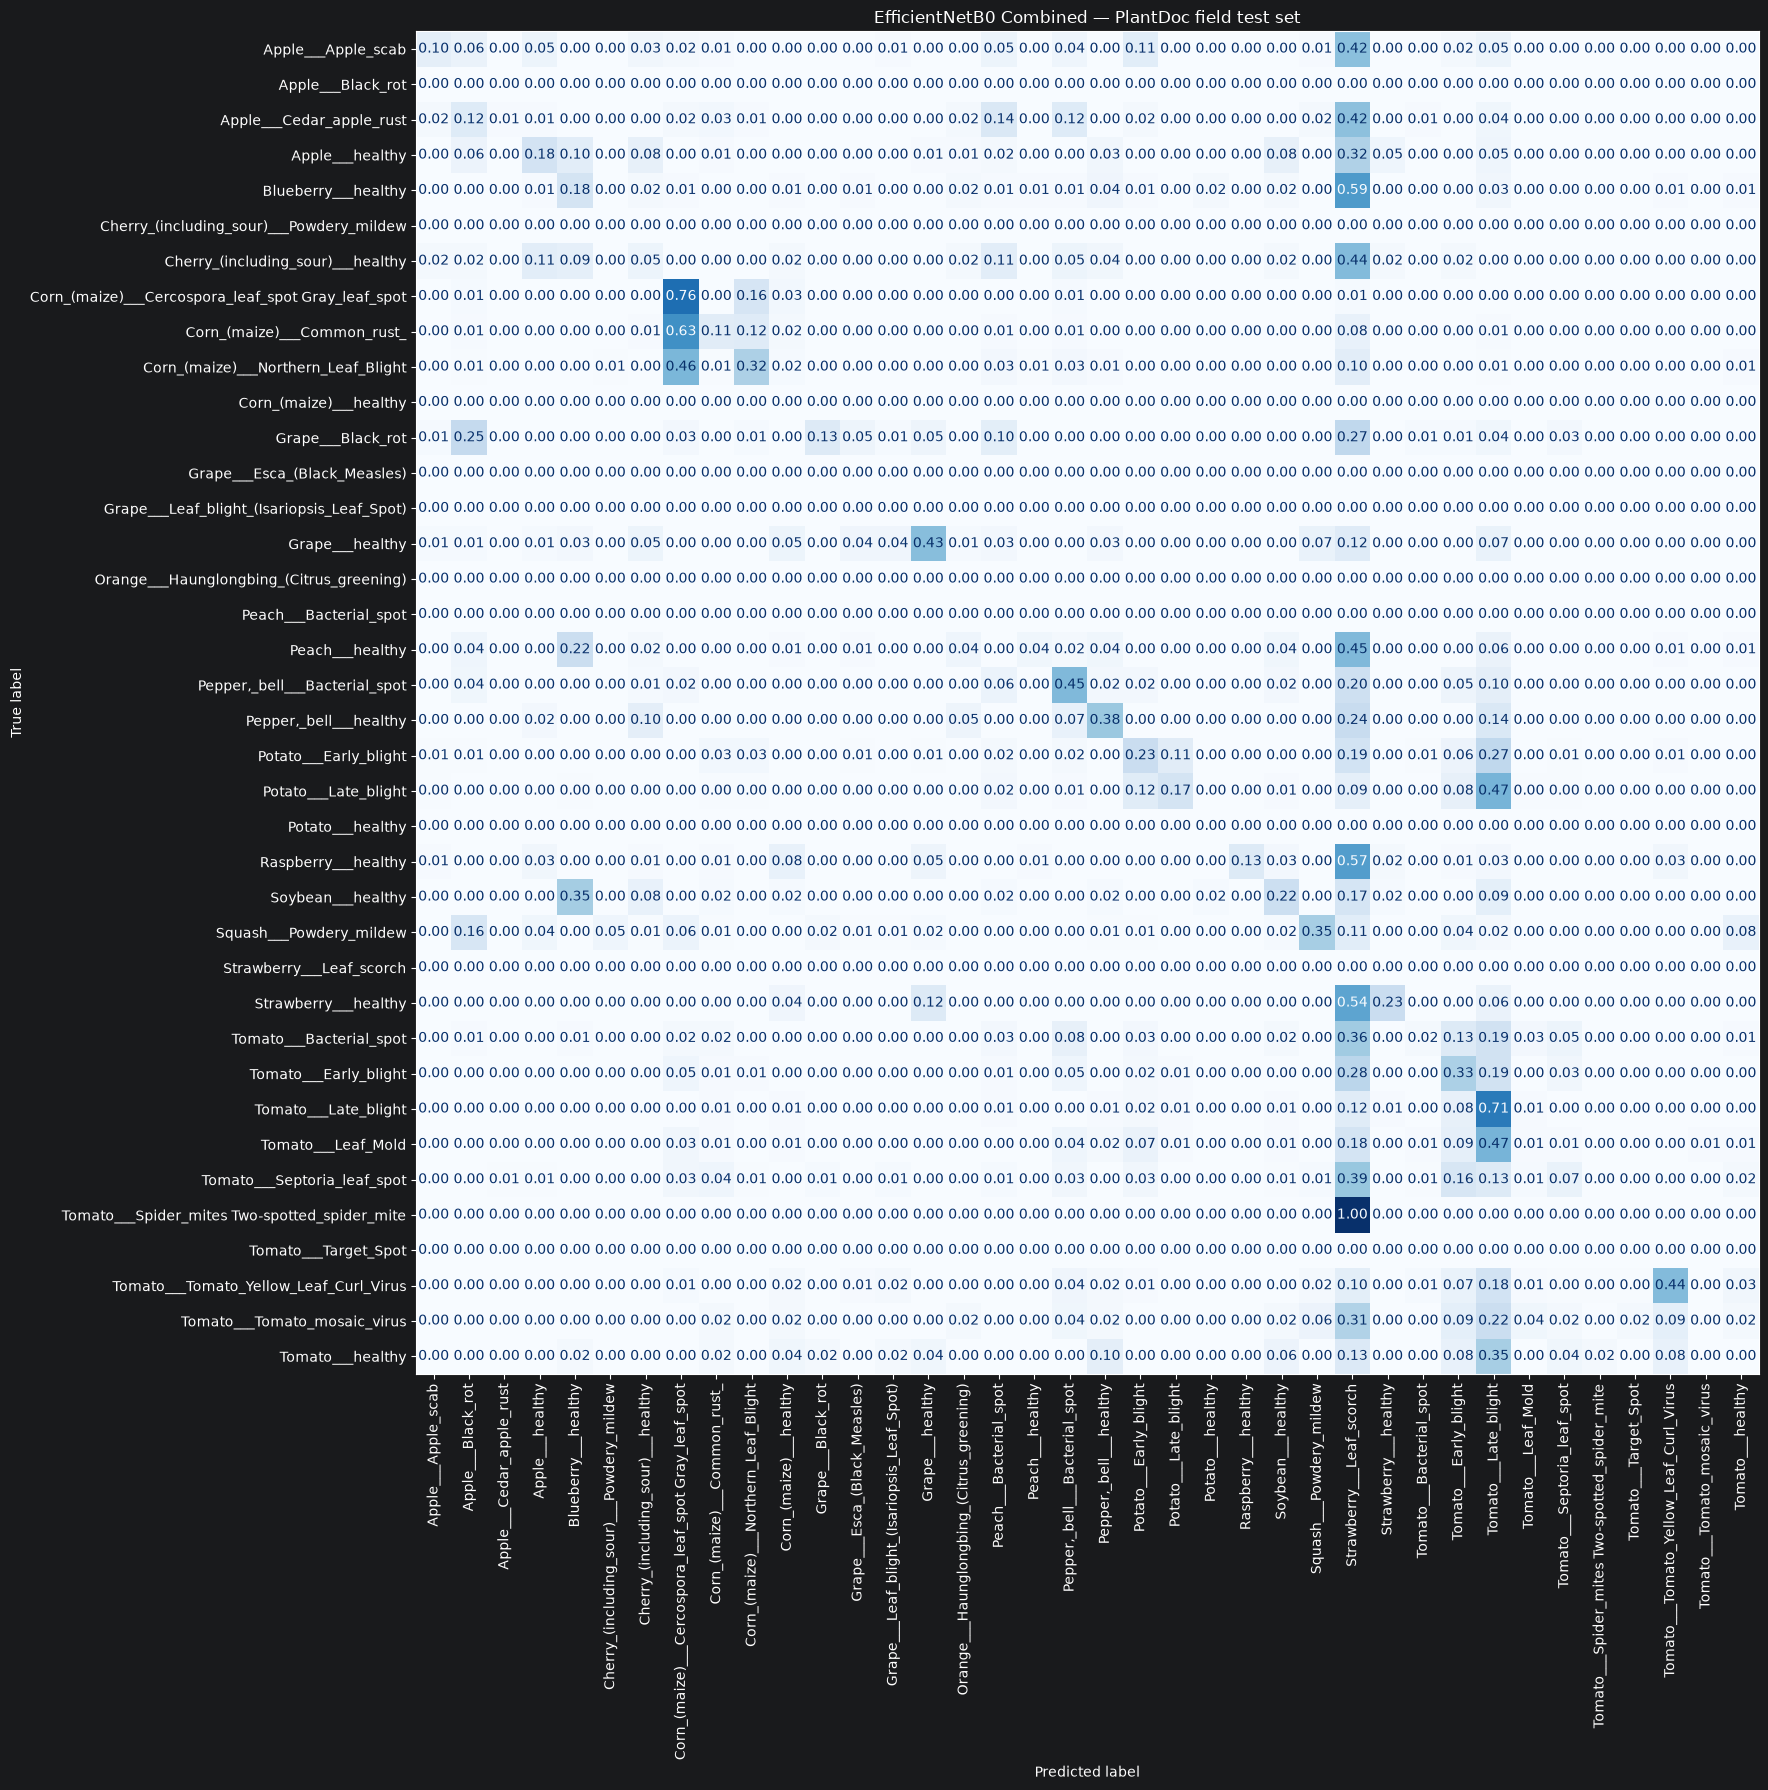

In [24]:
if augmentation_results:
    for strategy_name, result in augmentation_results.items():
        safe_name = strategy_name.lower()
        plot_confusion_matrix_from_results(
            result["lab"],
            f"EfficientNetB0 {strategy_name} — PlantVillage laboratory test set",
            f"{safe_name}_lab_confusion_matrix.png"
        )
        plot_confusion_matrix_from_results(
            result["field"],
            f"EfficientNetB0 {strategy_name} — PlantDoc field test set",
            f"{safe_name}_field_confusion_matrix.png"
        )
else:
    print("No augmentation experiment results are available yet.")


## 25. Compare augmentation performance drops

For RQ7.2, the most important outcome is field robustness. The plots compare PlantDoc macro-F1 and the laboratory-to-field macro-F1 gap across the no-augmentation baseline and all four augmentation strategies.


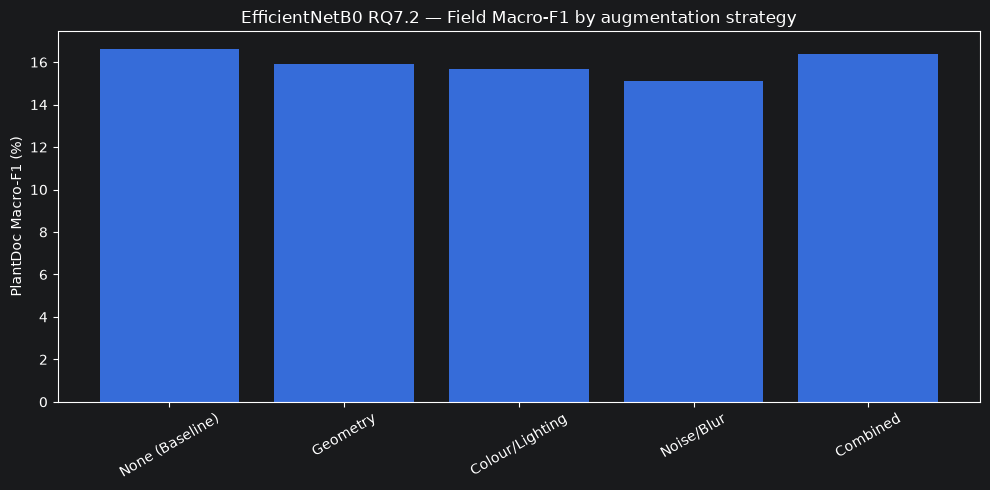

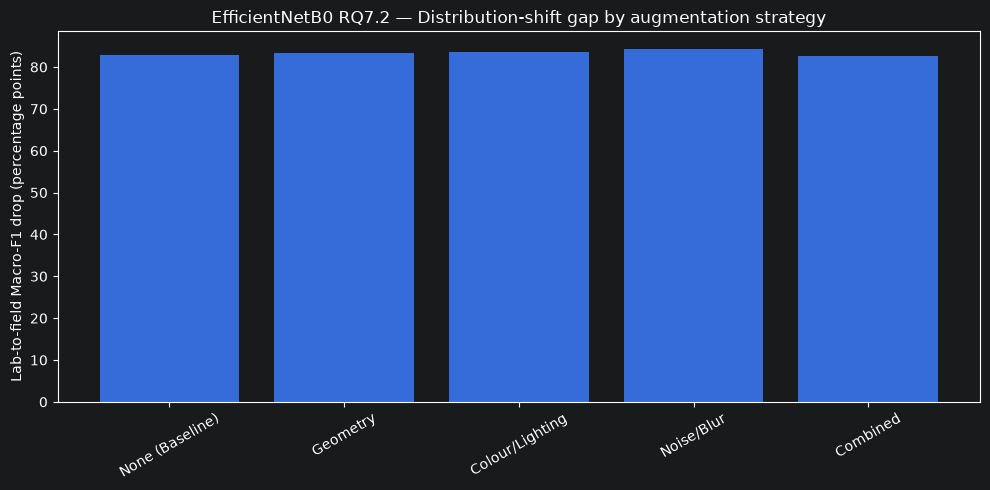

In [25]:
if len(comparison_df) > 0:
    plot_df = comparison_df.copy()

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(plot_df["Augmentation"], plot_df["Field Macro-F1 (%)"])
    ax.set_ylabel("PlantDoc Macro-F1 (%)")
    ax.set_title("EfficientNetB0 RQ7.2 — Field Macro-F1 by augmentation strategy")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    fig.savefig(AUG_PLOTS_DIR / "field_macro_f1_by_augmentation.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(plot_df["Augmentation"], plot_df["Macro-F1 Drop (pp)"])
    ax.set_ylabel("Lab-to-field Macro-F1 drop (percentage points)")
    ax.set_title("EfficientNetB0 RQ7.2 — Distribution-shift gap by augmentation strategy")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    fig.savefig(AUG_PLOTS_DIR / "macro_f1_drop_by_augmentation.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("Comparison table is empty.")


## 26. Determine the best augmentation strategy

The primary criterion is **highest PlantDoc macro-F1**, because RQ7.2 focuses on generalisation to field conditions and macro-F1 gives each evaluated class equal importance. PlantDoc accuracy and the smallest lab-to-field macro-F1 drop are reported as supporting criteria.


In [26]:
if len(comparison_df) > 0:
    best_field_f1_idx = comparison_df["Field Macro-F1 (%)"].idxmax()
    best_field_acc_idx = comparison_df["Field Accuracy (%)"].idxmax()
    smallest_f1_drop_idx = comparison_df["Macro-F1 Drop (pp)"].idxmin()

    best_field_f1 = comparison_df.loc[best_field_f1_idx]
    best_field_acc = comparison_df.loc[best_field_acc_idx]
    smallest_f1_drop = comparison_df.loc[smallest_f1_drop_idx]

    print("=" * 72)
    print("RQ7.2 EFFICIENTNETB0 AUGMENTATION CONCLUSION")
    print("=" * 72)
    print(
        f"Best strategy by PlantDoc macro-F1: {best_field_f1['Augmentation']} "
        f"({best_field_f1['Field Macro-F1 (%)']:.2f}%)"
    )
    print(
        f"Best strategy by PlantDoc accuracy: {best_field_acc['Augmentation']} "
        f"({best_field_acc['Field Accuracy (%)']:.2f}%)"
    )
    print(
        f"Smallest lab-to-field macro-F1 drop: {smallest_f1_drop['Augmentation']} "
        f"({smallest_f1_drop['Macro-F1 Drop (pp)']:.2f} pp)"
    )

    baseline_row = comparison_df[
        comparison_df["Augmentation"] == "None (Baseline)"
    ].iloc[0]

    field_f1_gain = best_field_f1["Field Macro-F1 (%)"] - baseline_row["Field Macro-F1 (%)"]
    gap_reduction = baseline_row["Macro-F1 Drop (pp)"] - best_field_f1["Macro-F1 Drop (pp)"]

    print("\nCompared with the no-augmentation baseline:")
    print(f"Field macro-F1 change: {field_f1_gain:+.2f} percentage points")
    print(f"Macro-F1 gap reduction: {gap_reduction:+.2f} percentage points")

    conclusion = pd.DataFrame([{
        "Primary best strategy": best_field_f1["Augmentation"],
        "Best field Macro-F1 (%)": best_field_f1["Field Macro-F1 (%)"],
        "Field Macro-F1 improvement vs baseline (pp)": round(field_f1_gain, 2),
        "Macro-F1 gap reduction vs baseline (pp)": round(gap_reduction, 2),
        "Best field-accuracy strategy": best_field_acc["Augmentation"],
        "Smallest-gap strategy": smallest_f1_drop["Augmentation"],
    }])
    display(conclusion)
    conclusion.to_csv(
        AUG_REPORTS_DIR / "rq7_2_efficientnetb0_best_augmentation_strategy.csv",
        index=False
    )
else:
    print("Run the augmentation experiments before selecting the best strategy.")


RQ7.2 EFFICIENTNETB0 AUGMENTATION CONCLUSION
Best strategy by PlantDoc macro-F1: None (Baseline) (16.62%)
Best strategy by PlantDoc accuracy: Combined (23.07%)
Smallest lab-to-field macro-F1 drop: Combined (82.63 pp)

Compared with the no-augmentation baseline:
Field macro-F1 change: +0.00 percentage points
Macro-F1 gap reduction: +0.00 percentage points


,Primary best strategy,Best field Macro-F1 (%),Field Macro-F1 improvement vs baseline (pp),Macro-F1 gap reduction vs baseline (pp),Best field-accuracy strategy,Smallest-gap strategy
0,None (Baseline),16.62,0.0,0.0,Combined,Combined


## 27. RQ7.2 completion checklist

After Sections 19–26 execute successfully, this EfficientNetB0 notebook contains:

- baseline PlantVillage and PlantDoc confusion matrices;
- geometry augmentation experiment;
- colour/lighting augmentation experiment;
- noise/blur augmentation experiment;
- combined augmentation experiment;
- independent EfficientNetB0 retraining for every augmentation strategy;
- laboratory-set evaluation for every strategy;
- PlantDoc field-set evaluation for every strategy;
- accuracy and macro-F1 lab-to-field performance-drop comparison; and
- automatic determination of the best augmentation strategy.

Together with the unchanged baseline sections, these outputs provide the EfficientNetB0 evidence needed to answer RQ7.2.


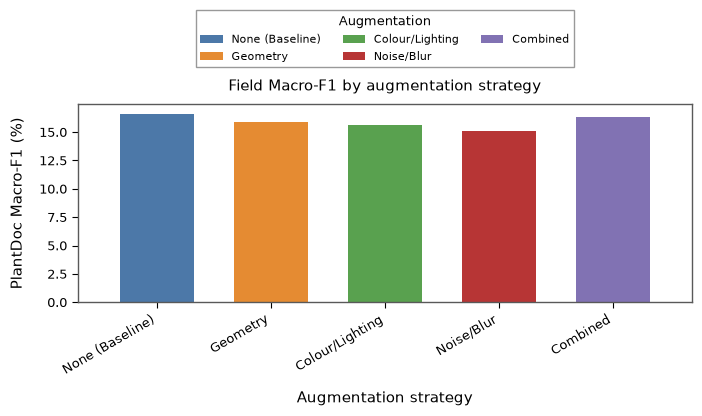

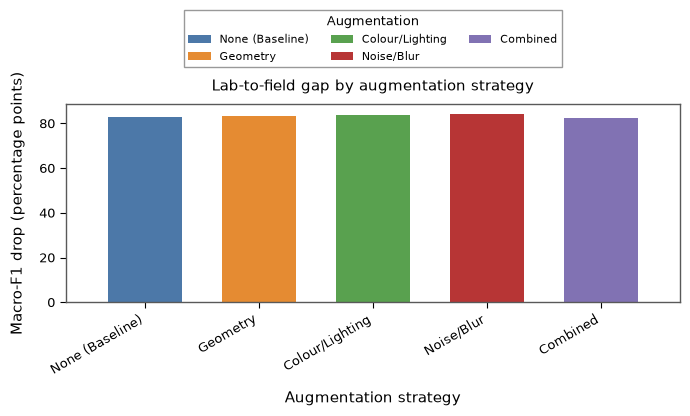

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if len(comparison_df) > 0:
    plot_df = comparison_df.copy()
    AUG_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

    labels = plot_df["Augmentation"].astype(str).tolist()
    x = np.arange(len(labels))

    palette = ["#4C78A8", "#E58B32", "#59A14F", "#B73535", "#8172B3"]
    colours = [palette[i % len(palette)] for i in range(len(labels))]

    legend_handles = [
        Patch(facecolor=colour, label=label)
        for label, colour in zip(labels, colours)
    ]

    style = {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": False,
        "axes.spines.top": True,
        "axes.spines.right": True,
        "axes.spines.bottom": True,
        "axes.spines.left": True,
        "text.color": "black",
        "axes.labelcolor": "black",
        "xtick.color": "black",
        "ytick.color": "black",
    }


    def plot_comparison(column, ylabel, title, filename):
        fig, ax = plt.subplots(figsize=(7, 4.5))

        ax.bar(
            x,
            plot_df[column],
            width=0.65,
            color=colours,
            edgecolor="none"
        )

        # Axis labels and tick labels.
        ax.set_xlabel("Augmentation strategy", labelpad=10)
        ax.set_ylabel(ylabel, labelpad=10)
        ax.set_title(title, pad=10)

        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=30, ha="right")
        ax.xaxis.set_visible(True)
        ax.yaxis.set_visible(True)

        # All four plot borders.
        ax.set_frame_on(True)
        for side in ["left", "right", "top", "bottom"]:
            ax.spines[side].set_visible(True)
            ax.spines[side].set_color("0.35")
            ax.spines[side].set_linewidth(1.0)

        ax.tick_params(
            axis="both",
            bottom=True,
            left=True,
            labelbottom=True,
            labelleft=True,
            direction="out",
            length=4,
            width=0.8
        )

        # Legend above the plot, avoiding overlap with the bars.
        ax.legend(
            handles=legend_handles,
            title="Augmentation",
            loc="lower center",
            bbox_to_anchor=(0.5, 1.16),
            ncol=min(3, len(labels)),
            fontsize=8,
            title_fontsize=9,
            frameon=True,
            fancybox=False,
            facecolor="white",
            edgecolor="0.6",
            framealpha=1
        )

        ax.grid(False)
        ax.margins(x=0.08)
        fig.tight_layout()

        for extension in ["png", "pdf"]:
            fig.savefig(
                AUG_PLOTS_DIR / f"{filename}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

        plt.show()
        plt.close(fig)


    with plt.rc_context(style):
        plot_comparison(
            "Field Macro-F1 (%)",
            "PlantDoc Macro-F1 (%)",
            "Field Macro-F1 by augmentation strategy",
            "field_macro_f1_by_augmentation"
        )

        plot_comparison(
            "Macro-F1 Drop (pp)",
            "Macro-F1 drop (percentage points)",
            "Lab-to-field gap by augmentation strategy",
            "macro_f1_drop_by_augmentation"
        )

else:
    print("Comparison table is empty.")

## 28. Calibration reporting — laboratory and PlantDoc

Report uncalibrated top-label confidence using 15 equal-width bins (configurable). ECE is the sample-weighted absolute difference between confidence and accuracy within bins; empty bins contribute zero. Reliability plots show mean confidence versus observed accuracy, with bin counts saved separately. ECE is bin-dependent and not a confidence interval. NLL is reported alongside it. All 38 model outputs remain eligible predictions.

This section uses probabilities collected during evaluation, without fitting on either test set. It does not change model weights or augmentation. Run after evaluations; skipped experiments are labelled rather than fabricated. For saved models lacking these arrays, rerun evaluation using the updated helper; no retraining is required if their original held-out membership is known. These results do not establish independence of previously trained models.


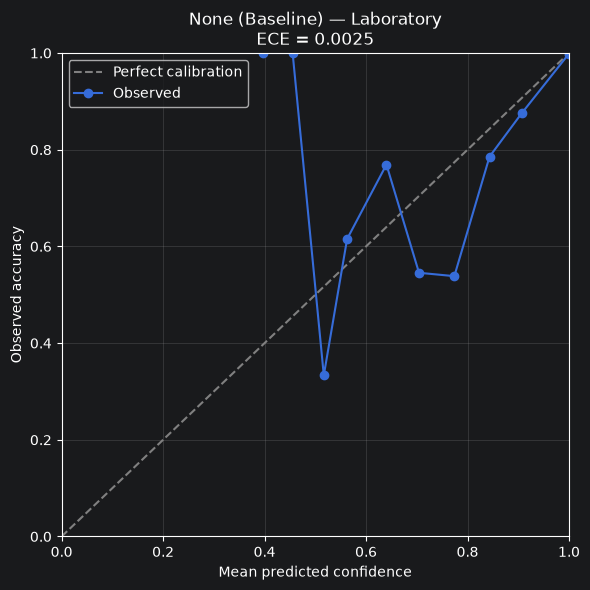

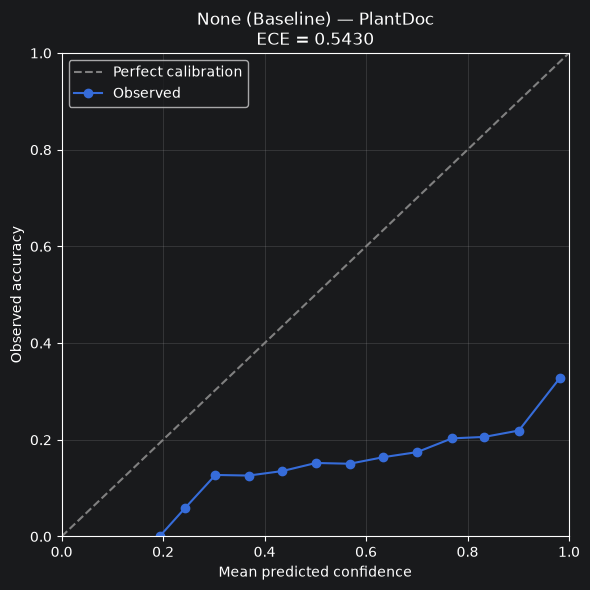

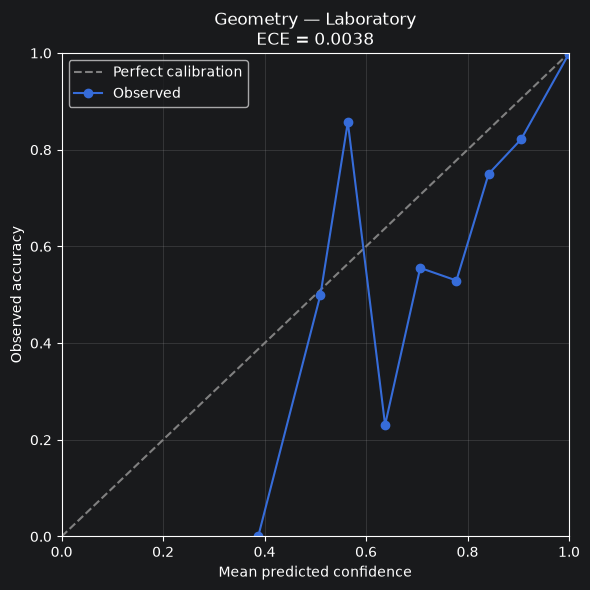

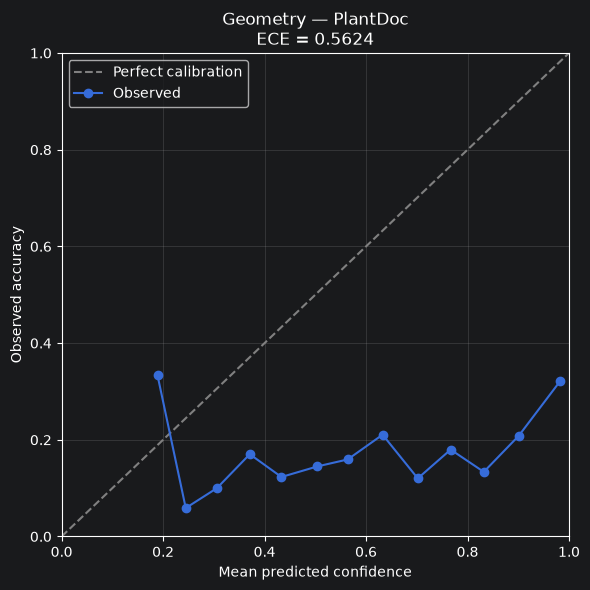

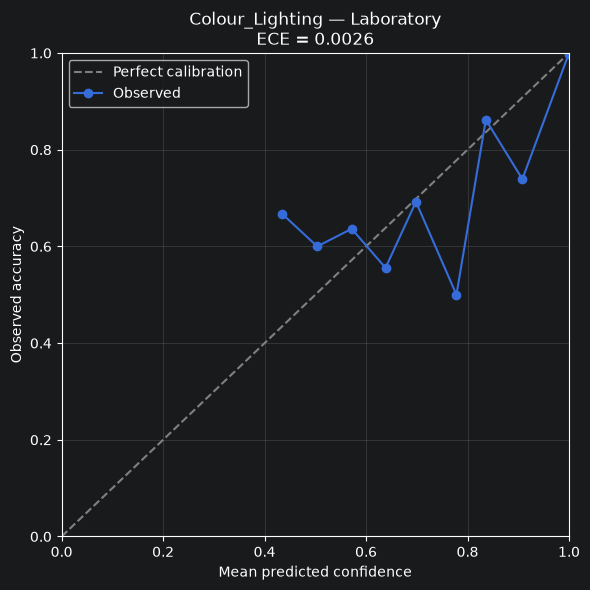

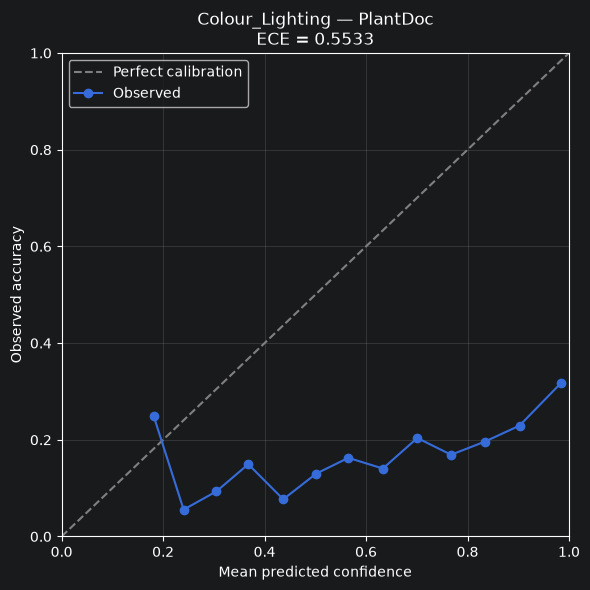

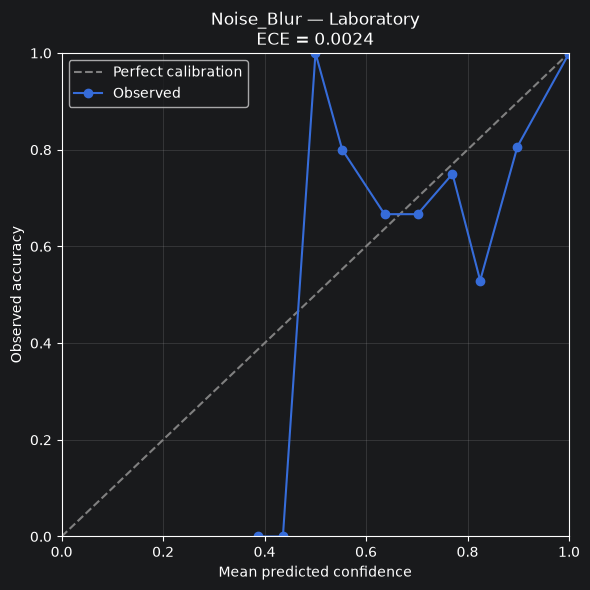

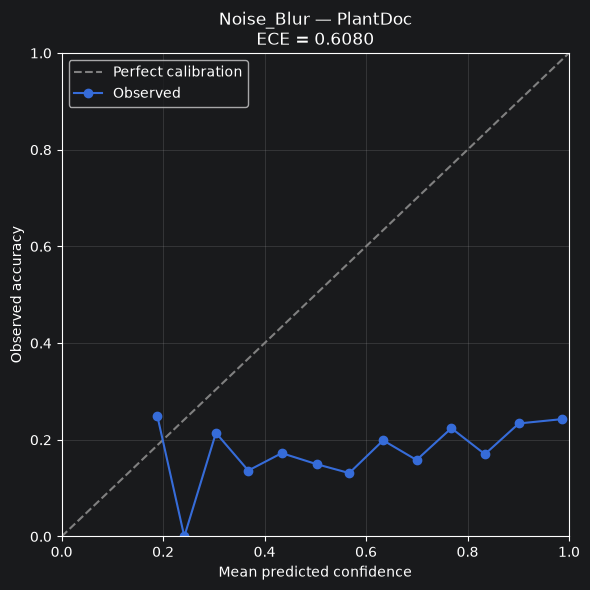

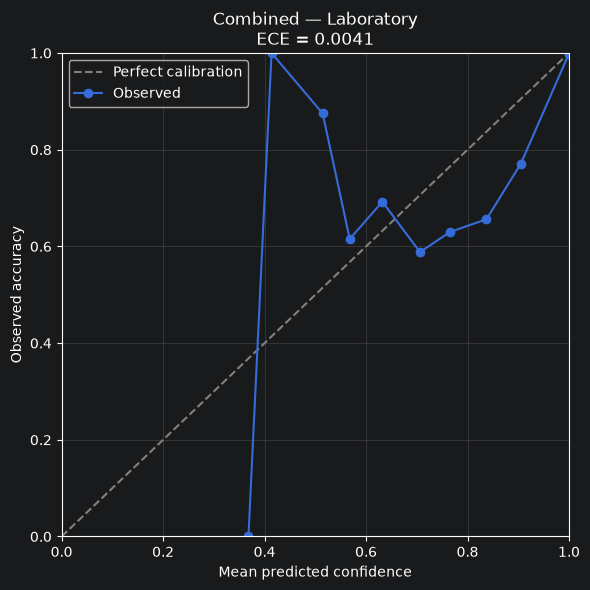

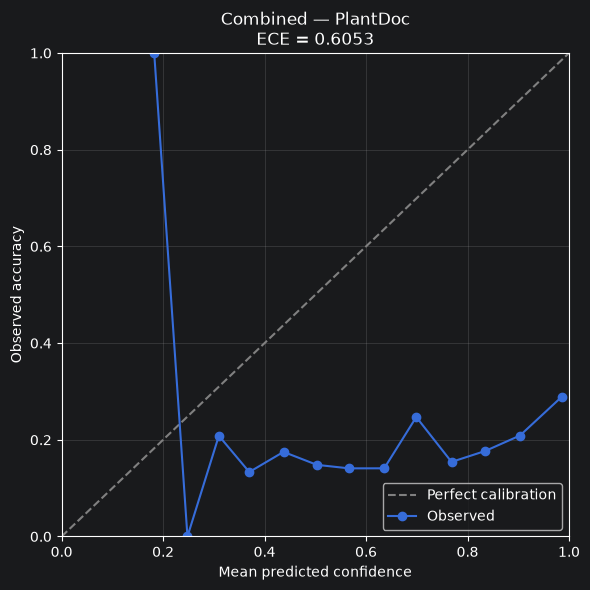

,strategy,domain,images,accuracy,macro_f1,ECE,ECE_percent,NLL,bins
0,None (Baseline),Laboratory,10709,0.995518,0.994319,0.002456,0.245551,0.015860,15
1,None (Baseline),PlantDoc,2922,0.228953,0.166202,0.542993,54.299251,6.528595,15
2,Geometry,Laboratory,10709,0.993463,0.991716,0.003785,0.378456,0.022665,15
3,Geometry,PlantDoc,2922,0.222108,0.159335,0.562375,56.237505,6.679397,15
4,Colour_Lighting,Laboratory,10709,0.994491,0.992389,0.002555,0.255478,0.019141,15
5,Colour_Lighting,PlantDoc,2922,0.220739,0.156718,0.553276,55.327591,6.385210,15
6,Noise_Blur,Laboratory,10709,0.995798,0.993968,0.002424,0.242398,0.016048,15
7,Noise_Blur,PlantDoc,2922,0.209103,0.150874,0.608001,60.800076,8.106875,15
8,Combined,Laboratory,10709,0.992810,0.990000,0.004136,0.413563,0.026402,15
9,Combined,PlantDoc,2922,0.230664,0.163735,0.605319,60.531890,7.758605,15


,strategy,training_seconds,estimated_energy_kwh,completed_fit_calls,training_minutes,assumed_average_power_w,energy_basis
0,Colour_Lighting,2771.915513,0.076998,2,46.198592,100.0,Illustrative 100 W whole-system assumption; re...
1,Combined,7157.050253,0.198807,2,119.284171,100.0,Illustrative 100 W whole-system assumption; re...
2,Geometry,7577.657784,0.210490,2,126.294296,100.0,Illustrative 100 W whole-system assumption; re...
3,Noise_Blur,3339.513908,0.092764,2,55.658565,100.0,Illustrative 100 W whole-system assumption; re...
4,None (Baseline),2395.544790,0.066543,2,39.925746,100.0,Illustrative 100 W whole-system assumption; re...


In [28]:
def calibration_statistics(y_true, probabilities, n_bins=15):
    y = np.asarray(y_true, dtype=int)
    p = np.asarray(probabilities, dtype=float)
    if p.ndim != 2 or len(y) != len(p) or not len(y):
        raise ValueError("Expected nonempty aligned labels and probability matrix.")
    if not np.isfinite(p).all() or (p < 0).any() or (p > 1).any():
        raise ValueError("Invalid probabilities.")
    if not np.allclose(p.sum(axis=1), 1, atol=1e-4):
        raise ValueError("Probability rows must sum to one.")
    if (y < 0).any() or (y >= p.shape[1]).any() or n_bins < 1:
        raise ValueError("Invalid labels or bin count.")
    confidence = p.max(axis=1)
    correct = (p.argmax(axis=1) == y).astype(float)
    ids = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    rows = []
    ece = 0.0
    for i in range(n_bins):
        mask = ids == i
        count = int(mask.sum())
        conf = float(confidence[mask].mean()) if count else np.nan
        acc = float(correct[mask].mean()) if count else np.nan
        if count:
            ece += count / len(y) * abs(acc - conf)
        rows.append({"bin_lower": i/n_bins, "bin_upper": (i+1)/n_bins,
                     "count": count, "mean_confidence": conf, "accuracy": acc})
    nll = float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-15, 1)).mean())
    return float(ece), nll, pd.DataFrame(rows)

calibration_rows = []
calibration_items = [("None (Baseline)", "Laboratory", lab_results),
                     ("None (Baseline)", "PlantDoc", field_results)]
for strategy, result in augmentation_results.items():
    calibration_items.extend([(strategy, "Laboratory", result["lab"]),
                              (strategy, "PlantDoc", result["field"])])
for strategy, domain, result in calibration_items:
    if result is None or "probabilities" not in result:
        print(f"Calibration skipped: {strategy}, {domain}; evaluation probabilities unavailable.")
        continue
    ece, nll, bins = calibration_statistics(result["y_true"], result["probabilities"], CALIBRATION_BINS)
    calibration_rows.append({"strategy": strategy, "domain": domain,
        "images": len(result["y_true"]), "accuracy": result["accuracy"],
        "macro_f1": result["macro_f1"], "ECE": ece, "ECE_percent": ece*100,
        "NLL": nll, "bins": CALIBRATION_BINS})
    stem = strategy.lower().replace(" ", "_").replace("/", "_").replace("(", "").replace(")", "") + "_" + domain.lower()
    bins.to_csv(REPORTS_DIR / f"{stem}_reliability_bins.csv", index=False)
    used = bins[bins["count"] > 0]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.plot(used["mean_confidence"], used["accuracy"], "o-", label="Observed")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted confidence",
           ylabel="Observed accuracy", title=f"{strategy} — {domain}\nECE = {ece:.4f}")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{stem}_reliability.png", dpi=180)
    plt.show(); plt.close(fig)
if calibration_rows:
    calibration_df = pd.DataFrame(calibration_rows)
    display(calibration_df)
    calibration_df.to_csv(REPORTS_DIR / "calibration_summary.csv", index=False)
if training_resource_rows:
    display(pd.read_csv(REPORTS_DIR / "training_resource_summary.csv"))
